# Postprocessing
### Import libraries

In [1]:
import os
import sys
import copy
import time
import importlib
import numpy as np
import tensorflow as tf
import joblib as jl
import h5py
import pandas as pd

threads = 4

from tqdm import tqdm

In [2]:
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
%matplotlib notebook

In [3]:
# # Get colors list
# colors = mpl.rcParams['axes.prop_cycle'].by_key()['color']*10

# # Font parameters
# mpl.rcParams['text.latex.preamble'].join([
#     r'\usepackage{amsmath}',
#     r'\boldmath',
#     r'\usepackage{pifont}',
#     r'\usepackage{tikz}',
#     r'\usepackage[utf8]{inputenc}'
# ])
# mpl.rcParams['font.family'] = 'lmodern'

# # Tick parameters
# mpl.rcParams['xtick.labelsize'] = 40
# mpl.rcParams['ytick.labelsize'] = 40
# mpl.rcParams['xtick.major.size'] = 20
# mpl.rcParams['xtick.major.width'] = 2
# mpl.rcParams['xtick.minor.size'] = 10
# mpl.rcParams['xtick.minor.width'] = 2

# # Tick parameters
# mpl.rcParams['axes.labelsize'] = 40
# mpl.rcParams['axes.titlesize'] = 40
# mpl.rcParams['legend.fontsize'] = 35


### Initialize SurQCT input parameters
Global inputs

In [ ]:
# Paths
WORKSPACE = '/home/zanardi/WORKSPACE/'
CoarseAIR = WORKSPACE + 'NeqPlasma/CoarseAIR/coarseair/'

# Molecules
levels = {
    'O2': WORKSPACE + '/database/levels/O2_UMN_log_nd.csv'
    'N2': ''
}
diat_pot = {
    'O2': CoarseAIR + 'dtb/Molecules/O2/UMN/FromUMN_Sorted.inp',
    'N2': CoarseAIR + 'dtb/Molecules/N2/LeRoy/MyLeroy_FromRobyn.inp'
}

# rates
qct_rates = {
    'O2': WORKSPACE + '/database/kinetics/HDF5/O3_UMN.hdf5',
    'N2': WORKSPACE + '/database/kinetics/HDF5/O3_UMN.hdf5'
}

Case inputs

In [4]:
n_processes = 3
T = 1500
excit_type = 'KInel'
molecules = ['O2']

indices = np.array([1, 10, 32, 34, 35, 81, 82, 98, 1000, 2000, 3000, 4581], dtype=int)
exo_endo = True

In [ ]:
# Model input features
diat_pot_inputs = {
    'branch': ['log_rorMin', 'ri', 'log_EVib', 'log_ERot'],
    'trunk': ['log_rorMin', 'ri', 'log_EVib', 'log_ERot']
}
branch_inp = [i + '_i' for i in inp_vars] + ['TTran_i']
trunk_inp = [i + '_Delta' for i in inp_vars] + ['TTran_Delta']
model_inp = branch_inp + trunk_inp

### Define PyCOMET and case directories paths

In [5]:
pcm_dir = os.environ['WORKSPACE_PATH'] + '/ML/PyCOMET/pycomet/'
case_dir = ''

../run6


In [6]:
if importlib.util.find_spec('pycomet') is None:
    sys.path.append(os.path.normpath(pcm_dir))
sys.path.append(os.path.normpath(case_dir))
cwd = os.getcwd()

### Import additional libraries

In [7]:
# PyCOMET ---------------------------------------------------------------------
from pycomet.utilities import utils
from pycomet.apps import functionObjects as fun

# Extra modules ---------------------------------------------------------------
# Inputs
import inputs

In [8]:
os.chdir(os.path.normpath(case_dir))

### Initialize network

In [9]:
net = fun._net(
    input_module=inputs
)


[PrODE]: Initializing 'OpNN' network ...


### Initialize PyCOMET model

In [10]:
from inputs.general import flags

for k in ('train', 'save'):
    flags[k] = 0
if flags['load'] not in (1, 2):
    utils.raise_value_err(
        "The network has to be restored from a saved or a checkpointed "
        "one. Modified the 'load' entry in the `flags` input variable."
    )
model = fun._model(
    flags=flags,
    input_module=inputs,
    net=net
)


[PrODE]: Building 'OpNN' network ...
Model: "SurQCT_OpNN"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 5)]          0                                            
__________________________________________________________________________________________________
input_2 (InputLayer)            [(None, 5)]          0                                            
__________________________________________________________________________________________________
branch_fn (SurQCTNormalization) (None, 5)            11          input_1[0][0]                    
__________________________________________________________________________________________________
trunk_fn (SurQCTNormalization)  (None, 5)            11          input_2[0][0]                    
__________________________________________________

### Read levels data

In [ ]:
lev_data = {}
diat_data = {}
n_lev = {}

for mol in range(molecules):
    lev_data[mol] = read_levels_data(levels[mol], tf.nest.flatten(diat_pot_inputs.values()))
    diat_data[mol] = read_diatdata(diat_pot[mol], mol, np.array([T]))
    n_lev[mol] = diat_data[mol].shape[0]

In [11]:
from Reading  import read_levelsdata, read_diatdata

In [12]:
OtherVar           = InputData.OtherVar
xVarsVec_i         = InputData.xVarsVec_i 
xVarsVec_Delta     = InputData.xVarsVec_Delta
xVarsVec           = list(set(xVarsVec_i) | set(xVarsVec_Delta))

xbranch = [(VarName + '_i') for VarName in xVarsVec_i]
Tbranch = ['TTran_i']
xtrunk = [(VarName + '_Delta') for VarName in xVarsVec_Delta]
Ttrunk = ['TTran_Delta']
xTrainingVars = xbranch + Tbranch + xtrunk + Ttrunk

xVarsVec_i         = InputData.xVarsVec_i + ['vqn','jqn']
xVarsVec_Delta     = InputData.xVarsVec_Delta
xVarsVec           = list(set(xVarsVec_i) | set(xVarsVec_Delta))

NMolecules         = len(InputData.PathToDiatFile)
LevelsData = []
DiatData   = []
NLevels    = []

for name in range(NMolecules):
    
    LevelsDataTemp = read_levelsdata(InputData.PathToLevelsFile[iMol], xVarsVec, '')
    LevelsData.append(LevelsDataTemp)

    DiatDataTemp = read_diatdata(InputData.PathToDiatFile[iMol], InputData.Molecules[iMol], np.array([TTran]), np.array([TTran]))
    DiatData.append(DiatDataTemp)
    
    NLevelsTemp    = DiatDataTemp.shape[0]
    NLevels.append(NLevelsTemp)

[SurQCT]:   Reading Molecular Levels Data from: /home/venturi/WORKSPACE//Air_Database/Run_0D/database/levels/O2_UMN_log_nd.csv
[SurQCT]:   Reading Molecular Levels Data from: /home/venturi/WORKSPACE//CoarseAIR/coarseair/dtb/Molecules/O2/UMN/FromUMN_Sorted.inp
[SurQCT]:   Reading Molecular Levels Data from: /home/venturi/WORKSPACE//Air_Database/Run_0D/database/levels/O2_UMN_log_nd.csv
[SurQCT]:   Reading Molecular Levels Data from: /home/venturi/WORKSPACE//CoarseAIR/coarseair/dtb/Molecules/O2/UMN/FromUMN_Sorted.inp


### Read QCT rates from HDF5 file

In [13]:
# Reading Excitation Rates Data 
def read_kexcitdata(PathToHDF5File, TTra, TInt, NProcTypes):
    print('[SurQCT]:       Reading HDF5 File from: ' + PathToHDF5File + ' for Excitation Rates at Temperature ' + str(int(TTra)) + 'K')

    HDF5Exist_Flg = os.path.exists(PathToHDF5File)
    if (HDF5Exist_Flg):
        f = h5py.File(PathToHDF5File, 'a')
    else:
        f = {'key': 'value'}

    TStr = 'T_' + str(int(TTra)) + '_' + str(int(TInt)) + '/Rates/'
    grp  = f[TStr]

    Data  = grp["Inel"]
    KInel = Data[...]

    KOther = []
    for iProc in range(2, NProcTypes):
        ExchStr    = "Exch_" + str(iProc-1)
        Data       = grp[ExchStr] 
        KOtherTemp = Data[...]
        KOther.append(KOtherTemp)

    f.close()   


    return KInel, KOther


KInelMat, KExchMatList = read_kexcitdata(InputData.PathToHDF5File, TTran, TTran, NProcTypes)

if (ExcitType == 'KInel'):
    KExcit = KInelMat
elif (ExcitType == 'KExch'):
    KExcit = KExchMatList[0]
else:
    KExcit = KInelMat + KExchMatList[0]

[SurQCT]:       Reading HDF5 File from: /home/venturi/WORKSPACE//Air_Database/HDF5_Database/O3_UMN.hdf5 for Excitation Rates at Temperature 1500K


In [14]:
os.chdir(os.path.normpath(cwd))

# Postprocessing - Model analysis

[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   0%|          | 0/13 [00:00<?, ?it/s]

Level: 0; vqn: 0; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   8%|▊         | 1/13 [00:01<00:13,  1.10s/it]

Level: 2; vqn: 0; jqn:2


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  15%|█▌        | 2/13 [00:01<00:09,  1.21it/s]

...

[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  85%|████████▍ | 11/13 [00:06<00:00,  2.05it/s]

Level: 2999; vqn: 26; jqn:34


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  92%|█████████▏| 12/13 [00:06<00:00,  2.10it/s]

Level: 4580; vqn: 44; jqn:1


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes: 100%|██████████| 13/13 [00:07<00:00,  1.85it/s]
findfont: Font family ['lmodern'] not found. Falling back to DejaVu Sans.
findfont: Font family ['lmodern'] not found. Falling back to DejaVu Sans.


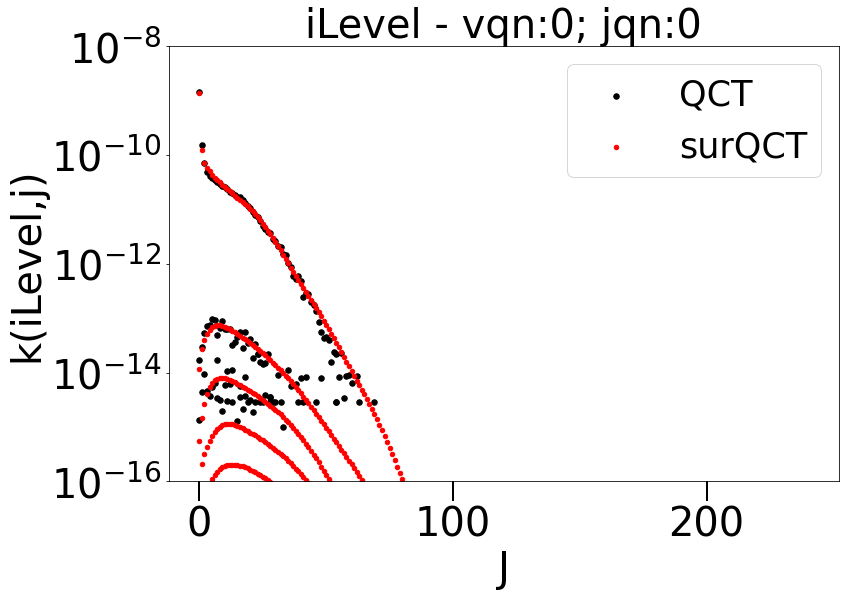

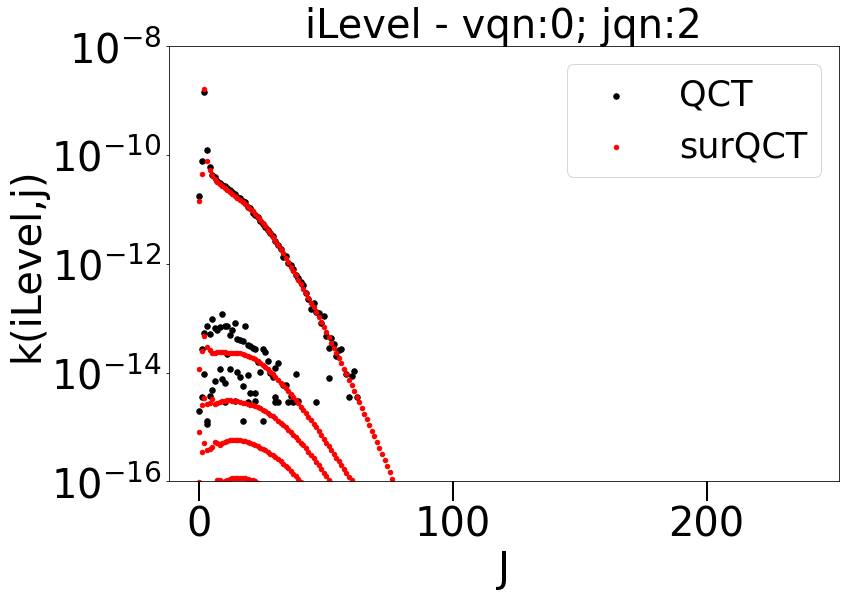

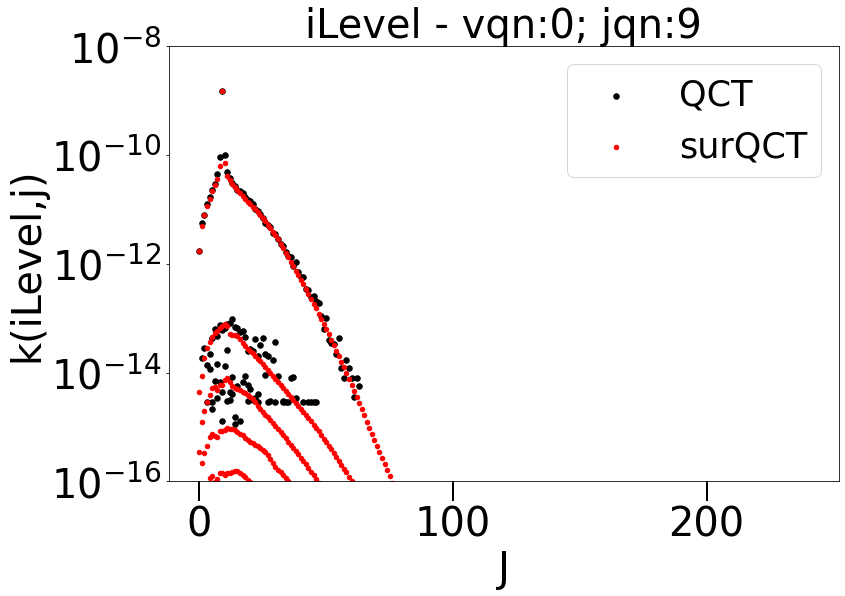

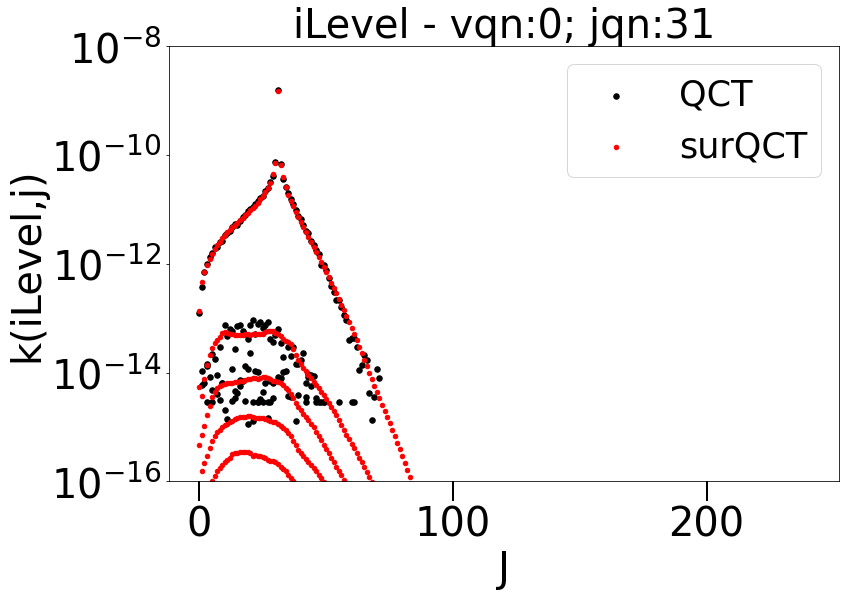

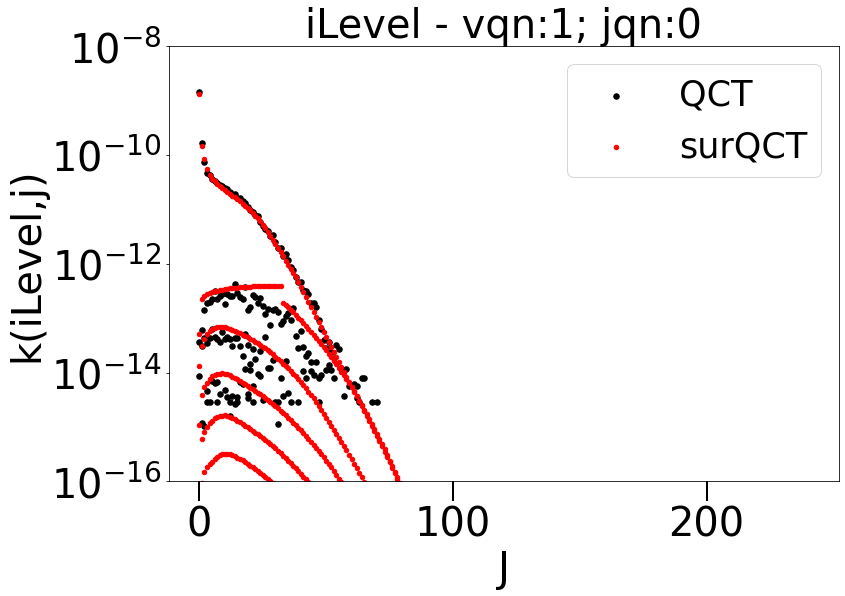

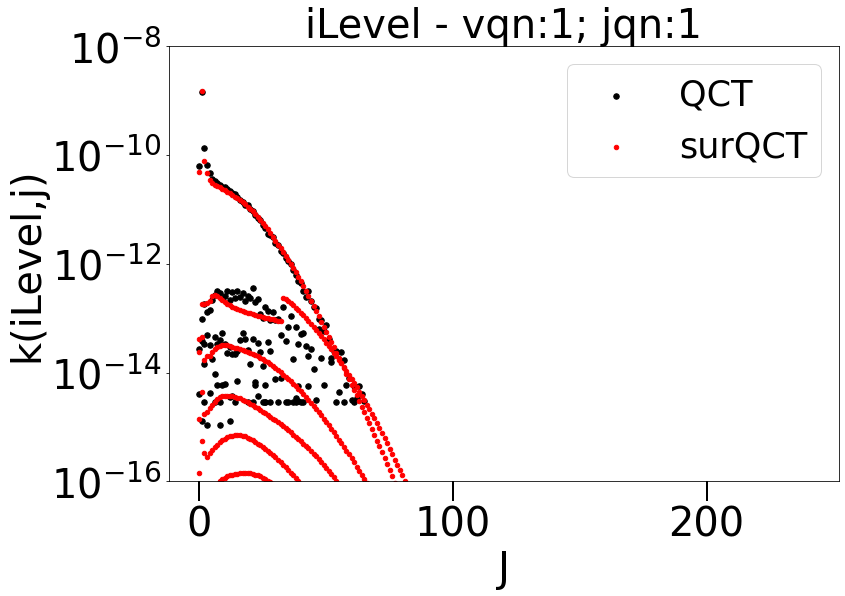

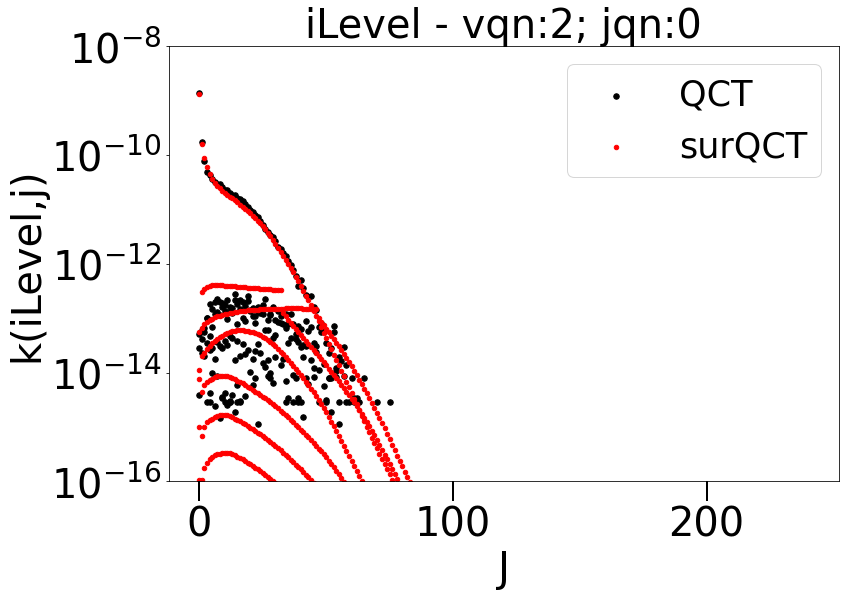

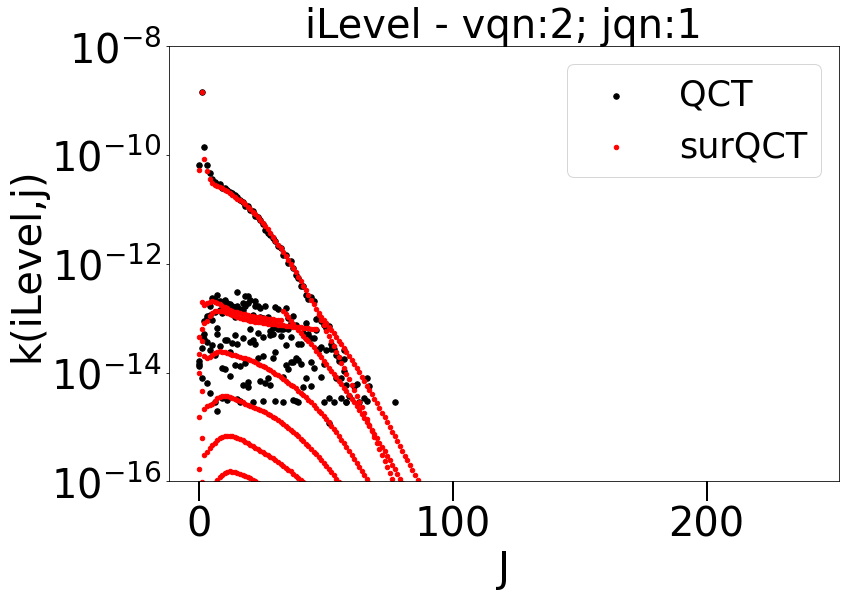

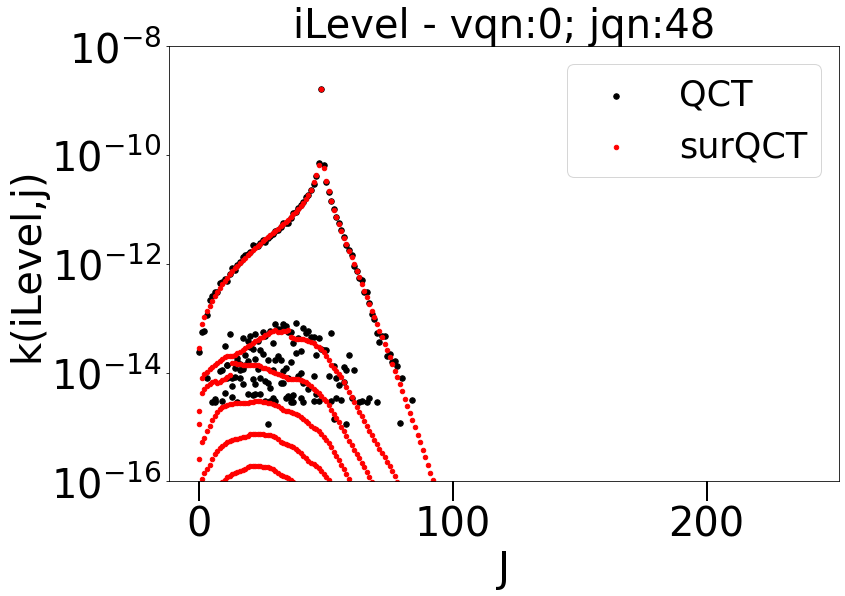

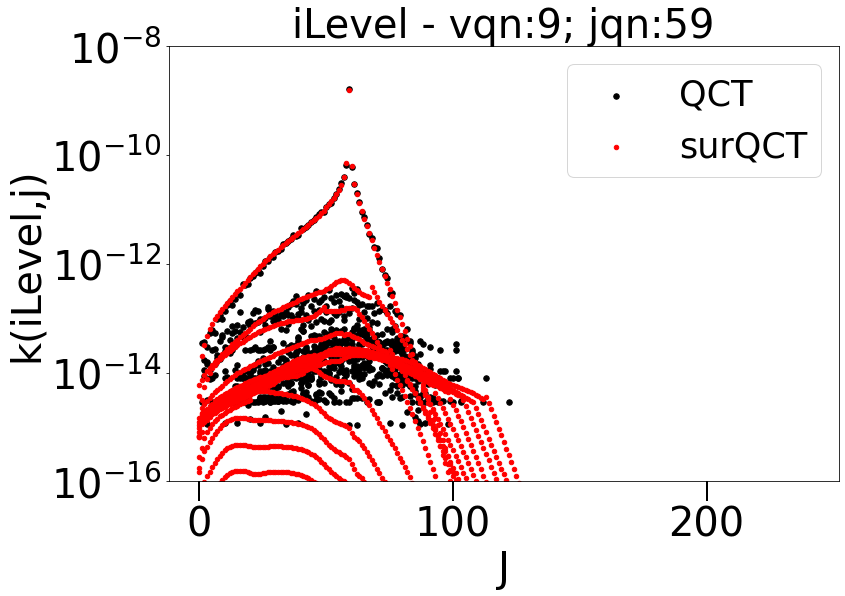

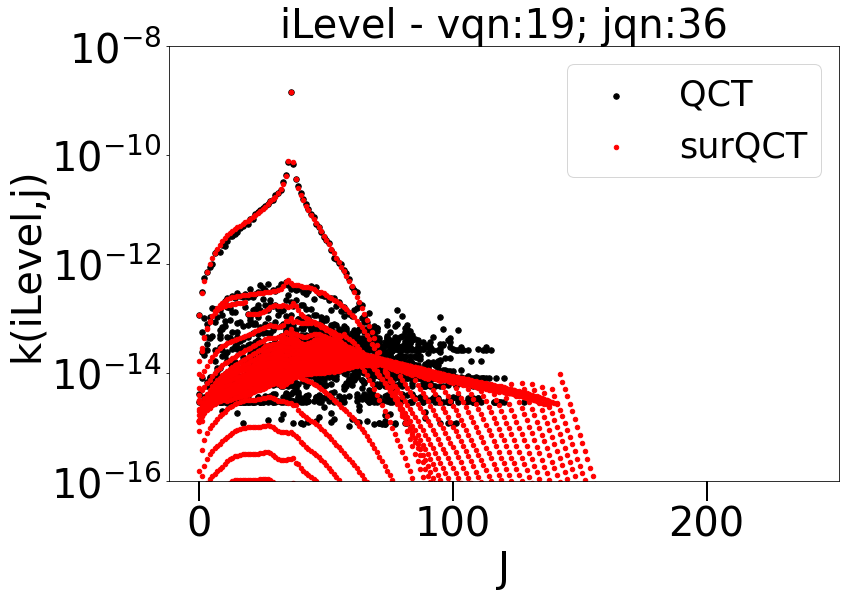

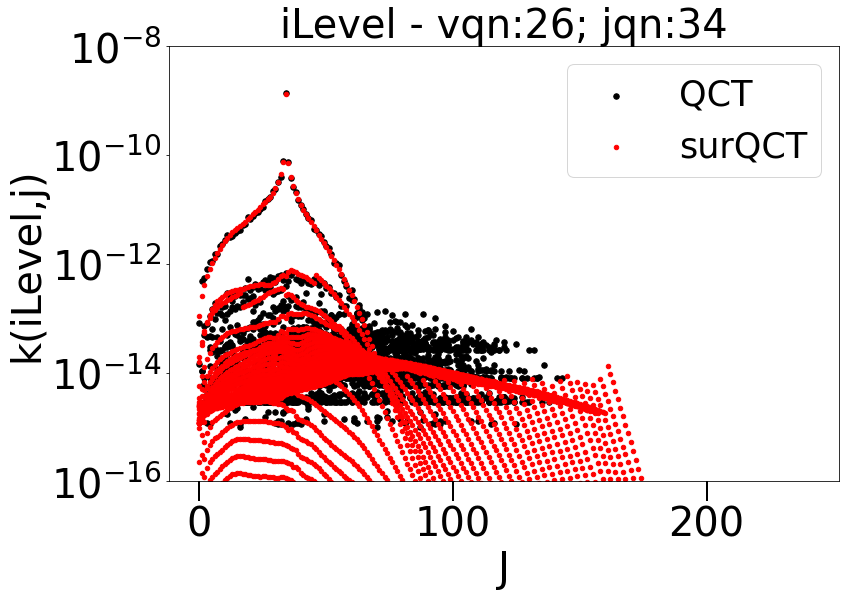

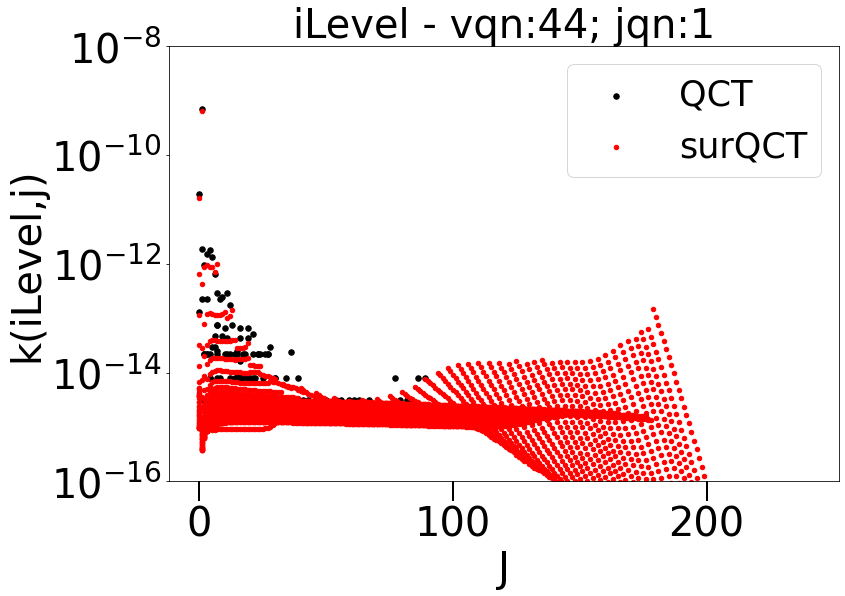

In [15]:
%matplotlib inline 
iIdxVec             = np.array([1, 3, 10, 32, 34, 35, 81, 82, 98, 1000, 2000, 3000, 4581], dtype=int)
# iIdxVec             = np.array([1,3], dtype=int)

### Loop on Initial States
Str = 'q_'+str(int(TTran))
for iIdx in tqdm(iIdxVec, desc='[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes'):
    iIdx -= 1
    print('Level: '+str(iIdx)+'; vqn: '+str(DiatData[0]['vqn'].to_numpy()[iIdx])+'; jqn:'+str(DiatData[0]['jqn'].to_numpy()[iIdx]))
    time.sleep(0.02)
    
    if (InputData.ExoEndoFlg):
        jIdxVec           = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] <= DiatData[0]['EInt'].to_numpy()[iIdx])]
        jIdxVecNo         = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] > DiatData[0]['EInt'].to_numpy()[iIdx])]
        RatioNo           = [DiatData[0][Str].to_numpy()[iIdx]/DiatData[1][Str].to_numpy()[jIdx] for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] > DiatData[0]['EInt'].to_numpy()[iIdx])]
    else:
        jIdxVec           = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    >= DiatData[0][Str].to_numpy()[iIdx])]
        jIdxVecNo         = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    < DiatData[0][Str].to_numpy()[iIdx])]
        RatioNo           = [DiatData[0][Str].to_numpy()[iIdx]/DiatData[1][Str].to_numpy()[jIdx] for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    < DiatData[0][Str].to_numpy()[iIdx])]
    jNLevels              = len(jIdxVec)
    jNLevelsNo            = len(jIdxVecNo)  
    
    ### FWD Rates
    iiIdxVec              = [iIdx]*jNLevels
    
    TTranVec              = np.ones((jNLevels))*TTran
    TTranDataTemp         = pd.DataFrame({'TTran': TTranVec})
    TTranDataTemp.index   = jIdxVec

    
    iLevelsDataTemp       = LevelsData[0].iloc[iiIdxVec,:].copy()
    iLevelsDataTemp.index = jIdxVec

    jLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    if (OtherVar == '_Delta'):
        jLevelsDataTemp   = iLevelsDataTemp.subtract(jLevelsDataTemp) 
    else:
        jLevelsDataTemp   = jLevelsDataTemp
    jLevelsDataTemp.index = jIdxVec
    
    kLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    kLevelsDataTemp.index = jIdxVec

    
    iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    iLevelsData.columns   = [(VarName + '_i') for VarName in iLevelsData.columns]
    
    jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
    jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

    kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    kLevelsData.columns   = [(VarName + '_j') for VarName in kLevelsData.columns]
    
    xTemp_FWD             = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)

    
    x1 = iLevelsData[xTrainingVars[0:5]].to_numpy()
    x2 = jLevelsData[xTrainingVars[5:10]].to_numpy()    

    x = [x1,x2]
        
    if (len(xTemp_FWD[xTrainingVars]) > 0):
        KExcit_NN_FWD          = np.exp( model.net.predict(x) ) / InputData.MultFact  
    
    ## BWD Rates
    iiIdxVec              = jIdxVecNo
    jIdxVec               = [iIdx]*jNLevelsNo
    
    TTranVec              = np.ones((jNLevelsNo))*TTran
    TTranDataTemp         = pd.DataFrame({'TTran': TTranVec})
    TTranDataTemp.index   = iiIdxVec

    
    iLevelsDataTemp       = LevelsData[0].iloc[iiIdxVec,:].copy()
    iLevelsDataTemp.index = iiIdxVec

    jLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy() 
    jLevelsDataTemp.index = iiIdxVec
    if (OtherVar == '_Delta'):
        jLevelsDataTemp   = iLevelsDataTemp.subtract(jLevelsDataTemp) 
    else:
        jLevelsDataTemp   = jLevelsDataTemp
    
    kLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    kLevelsDataTemp.index = iiIdxVec

    
    iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    iLevelsData.columns   = [(VarName + '_i') for VarName in iLevelsData.columns]
    
    jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
    jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

    kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    kLevelsData.columns   = [(VarName + '_j') for VarName in kLevelsData.columns]
    
    xTempp_BWD            = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)
    
    x1 = iLevelsData[xTrainingVars[0:5]].to_numpy()
    x2 = jLevelsData[xTrainingVars[5:10]].to_numpy()    
    x = [x1,x2]
    
    if (len(xTempp_BWD[xTrainingVars]) > 0):
        KExcit_NN_BWD          = np.exp( model.net.predict(x) ) / InputData.MultFact 
        KExcit_NN_BWD[:,0]     = KExcit_NN_BWD[:,0] / RatioNo

        iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
        iLevelsData.columns   = [(VarName + '_j') for VarName in iLevelsData.columns]

        jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
        jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

        kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
        kLevelsData.columns   = [(VarName + '_i') for VarName in kLevelsData.columns]

        xTemp_BWD             = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)
        
    ### Concatenating
        if (len(xTemp_FWD[xTrainingVars]) > 0):
            xTemp     = pd.concat([xTemp_FWD, xTemp_BWD], axis=0)
            KExcit_NN = np.concatenate((KExcit_NN_FWD, KExcit_NN_BWD), axis=0)
        else:
            xTemp     = xTemp_BWD
            KExcit_NN = KExcit_NN_BWD
    else:
        if (len(xTemp_FWD[xTrainingVars]) > 0):
            xTemp     = xTemp_FWD
            KExcit_NN = KExcit_NN_FWD   
    
    ### Plotting
    Mask     = KExcit[iIdx,:] > 1e-15
    
    j_color = xTemp['jqn_j'] % 2
    v_color = DiatData[1]['vqn'][Mask] == 1
    cmap=mpl.colors.ListedColormap(["navy","crimson","limegreen","gold","k","r","b","y","c"])
    cmap1=mpl.colors.ListedColormap(["k","limegreen"])
    fig = plt.figure(figsize=(12,8))

    label_plot = "iLevel - vqn:" + str(DiatData[0]['vqn'].to_numpy()[iIdx])+"; jqn:"+str(DiatData[0]['jqn'].to_numpy()[iIdx])
    plt.scatter(DiatData[1]['jqn'][Mask], KExcit[iIdx,Mask], c='k', s=30,label='QCT')
    plt.scatter(xTemp['jqn_j'], KExcit_NN[:,0], s=20, c='r', label='surQCT')
    plt.yscale('log')
    plt.legend(['QCT','surQCT'])
    plt.ylim([1.e-16, 1.e-8])
    plt.xlabel('J')
    plt.ylabel('k(iLevel,j)')
    plt.title(label_plot)

[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   0%|          | 0/45 [00:00<?, ?it/s]

[   1   34   81  138  203  275  355  440  531  626  728  833  943 1057
 1173 1294 1419 1545 1678 1812 1943 2083 2221 2365 2510 2655 2800 2950
 3096 3242 3387 3533 3677 3814 3952 4082 4200 4308 4393 4445 4488 4525
 4551 4571 4580]
Level: 0; vqn: 0; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   2%|▏         | 1/45 [00:00<00:28,  1.56it/s]

Level: 33; vqn: 1; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   4%|▍         | 2/45 [00:01<00:23,  1.82it/s]

...

[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  96%|█████████▌| 43/45 [00:20<00:00,  2.25it/s]

Level: 4570; vqn: 43; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  98%|█████████▊| 44/45 [00:20<00:00,  2.24it/s]

Level: 4579; vqn: 44; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes: 100%|██████████| 45/45 [00:21<00:00,  2.10it/s]


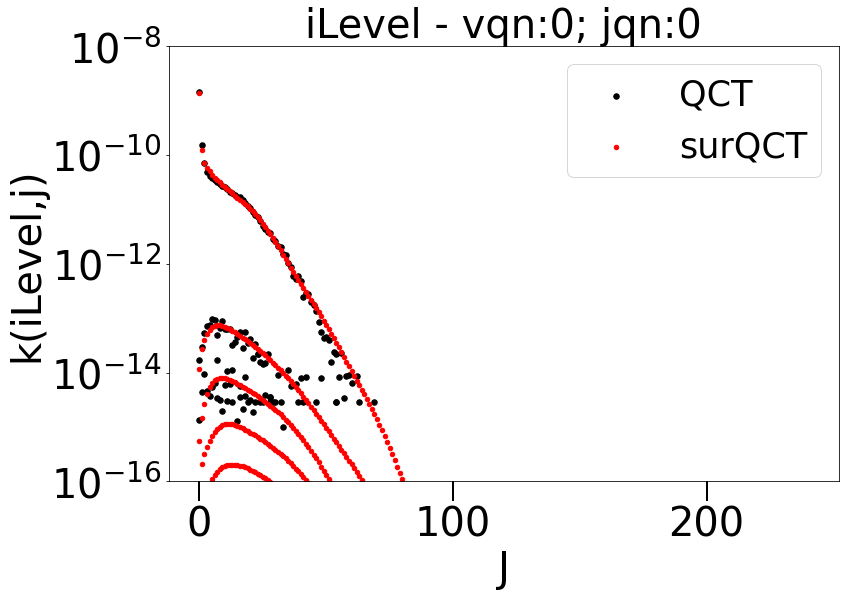

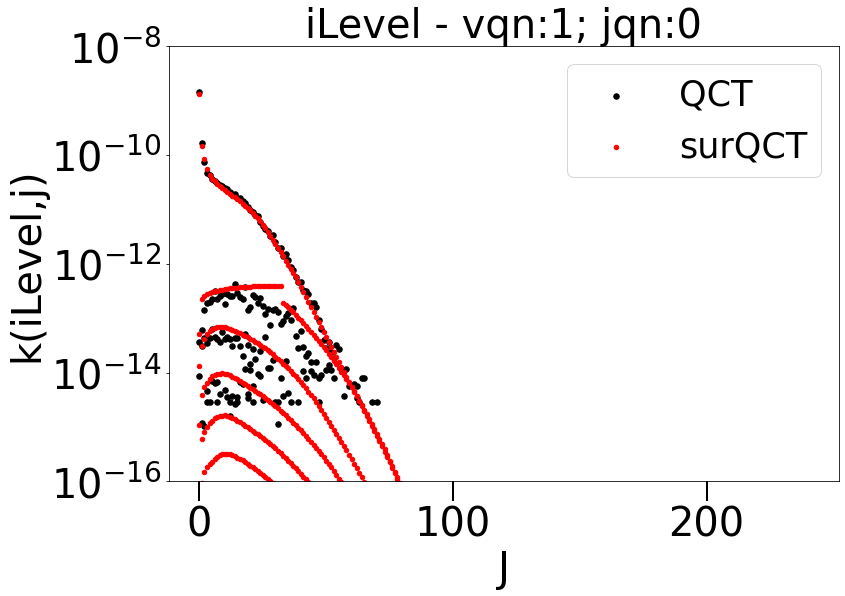

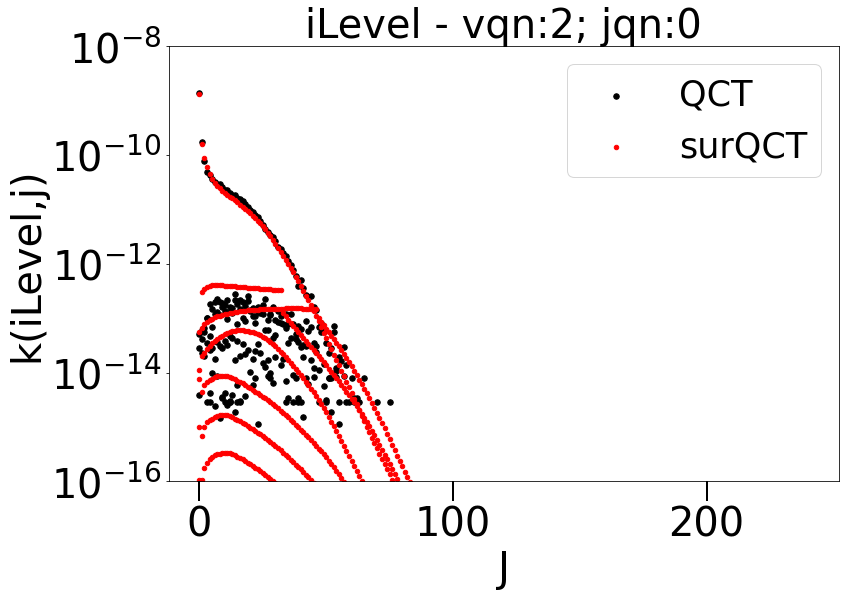

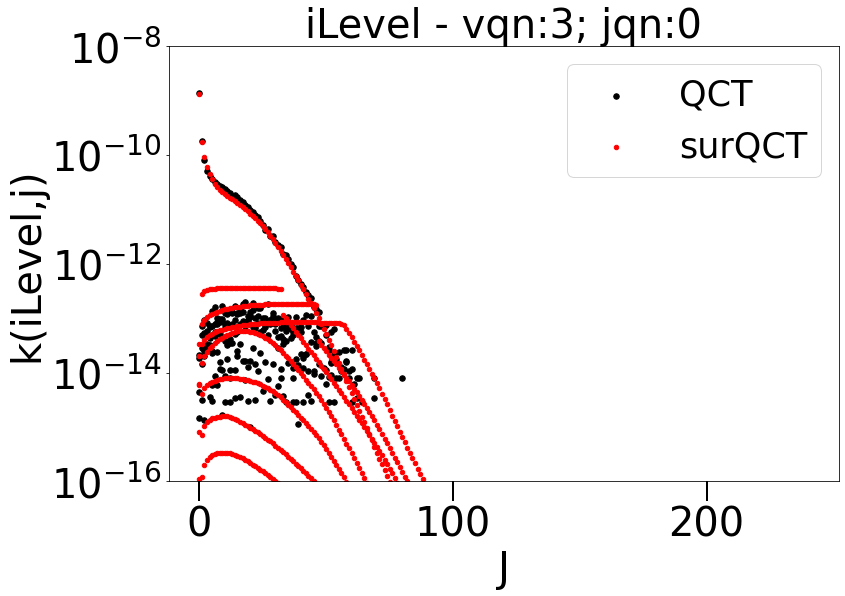

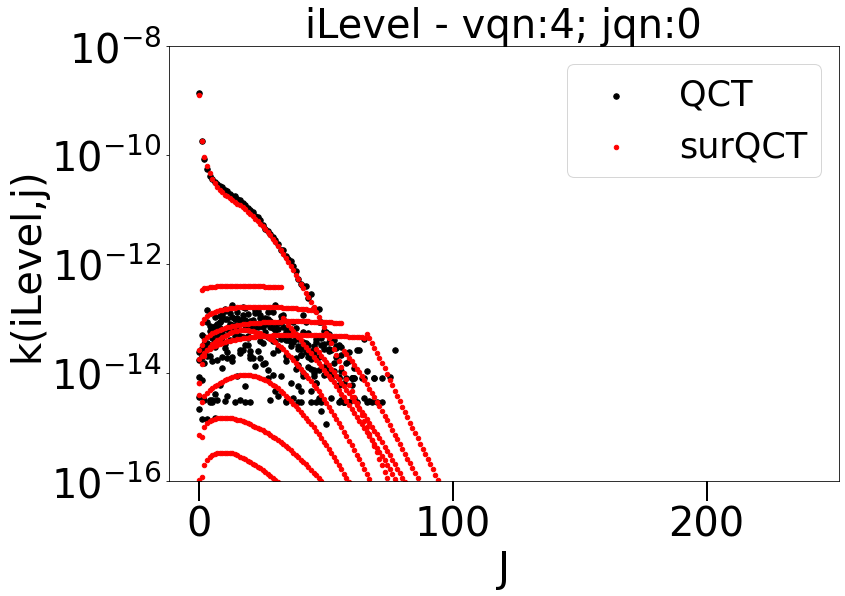

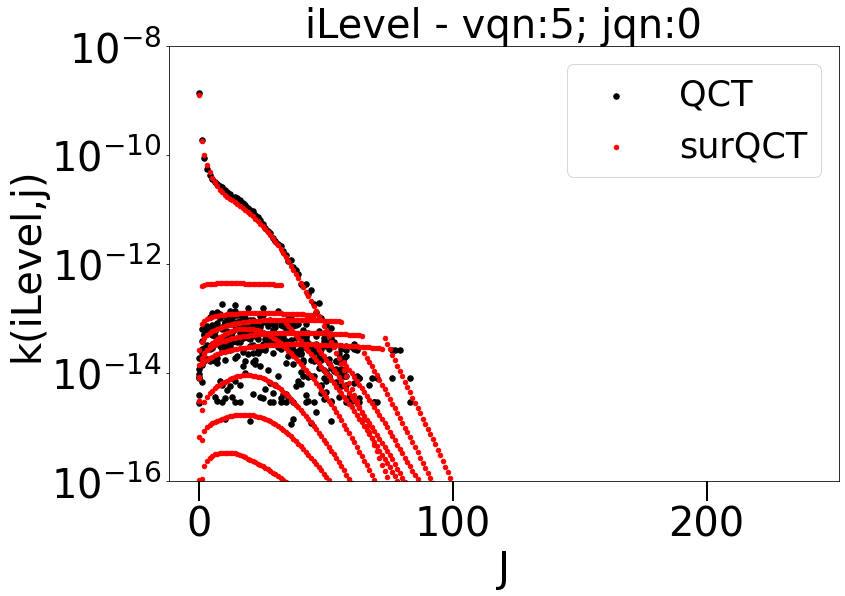

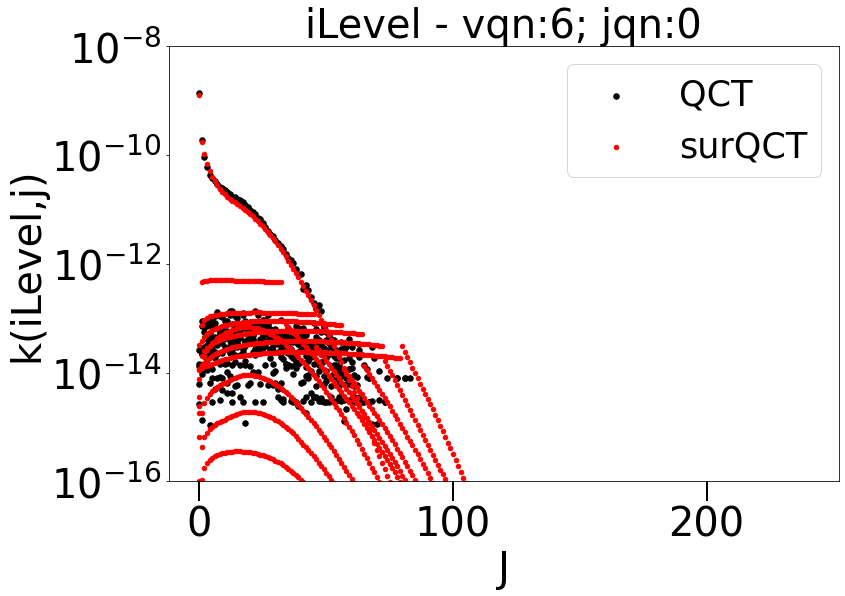

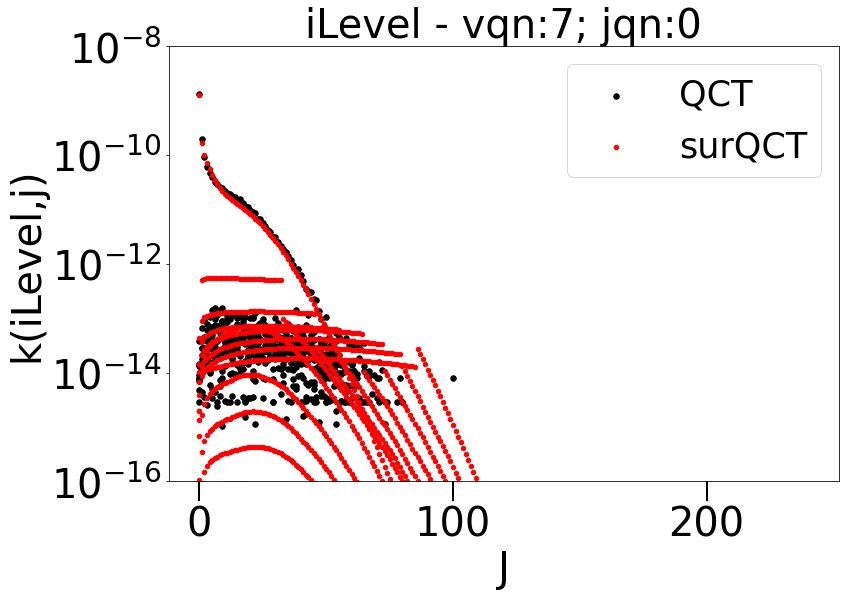

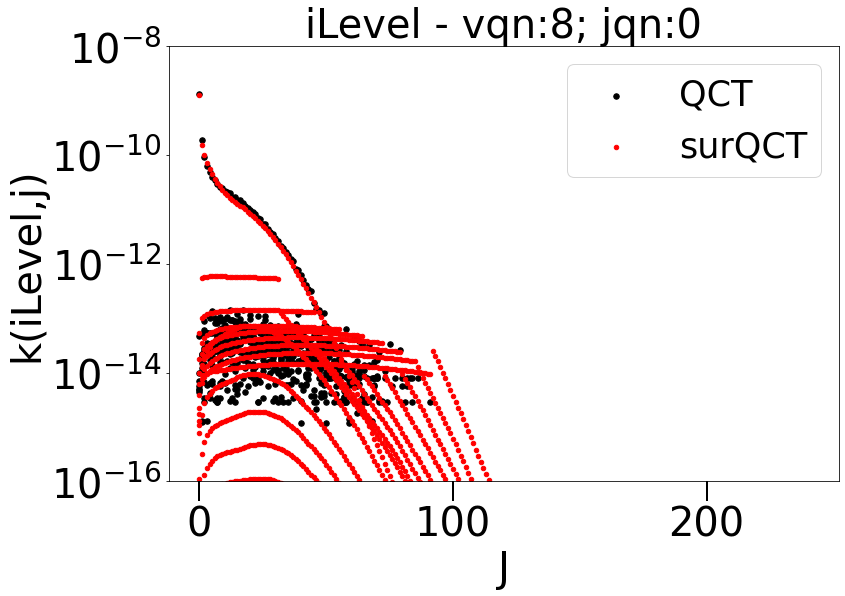

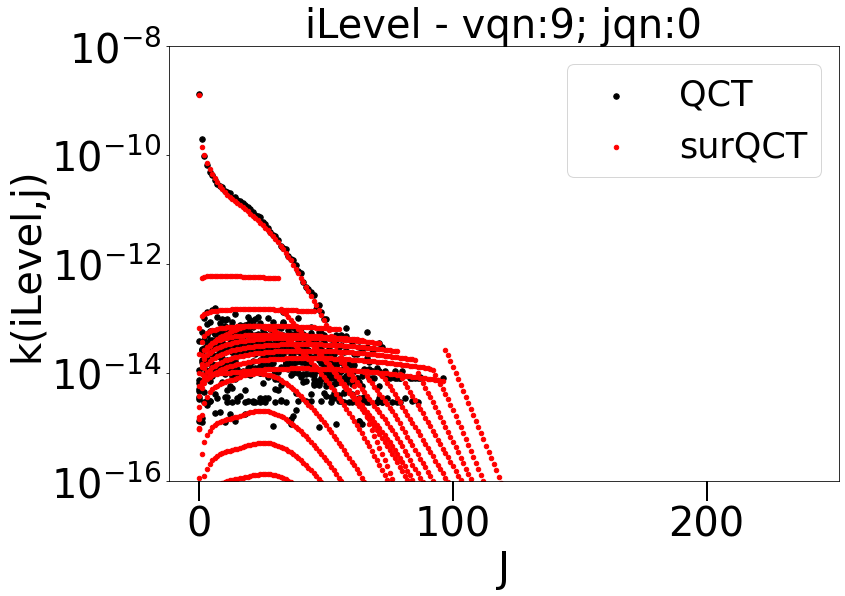

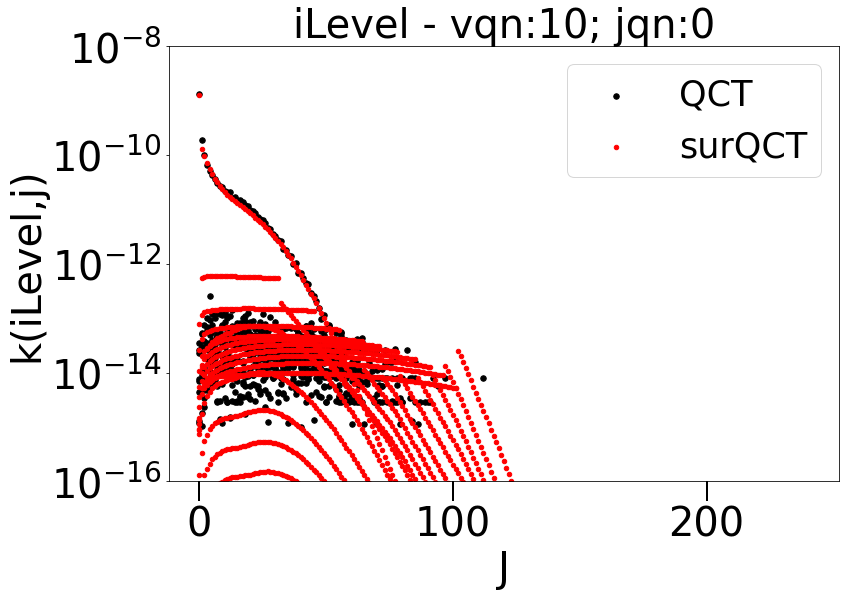

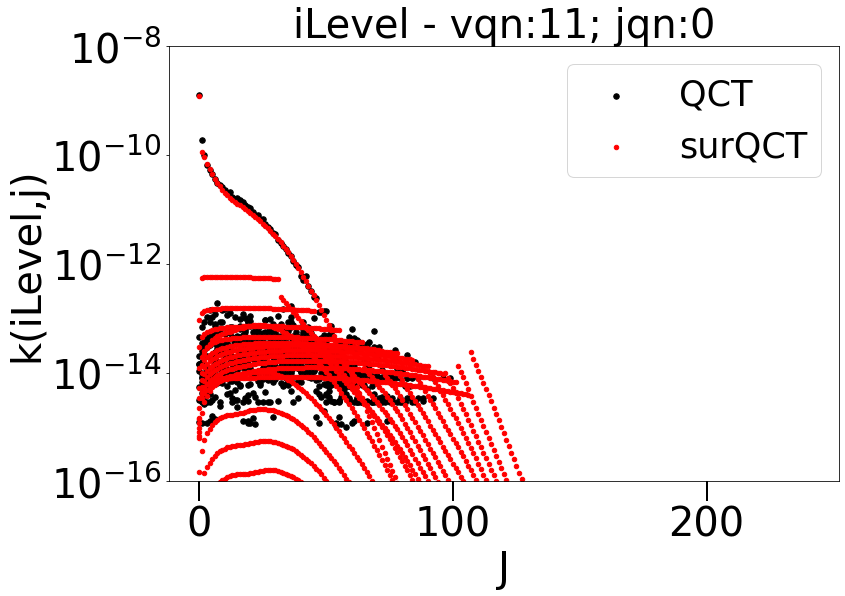

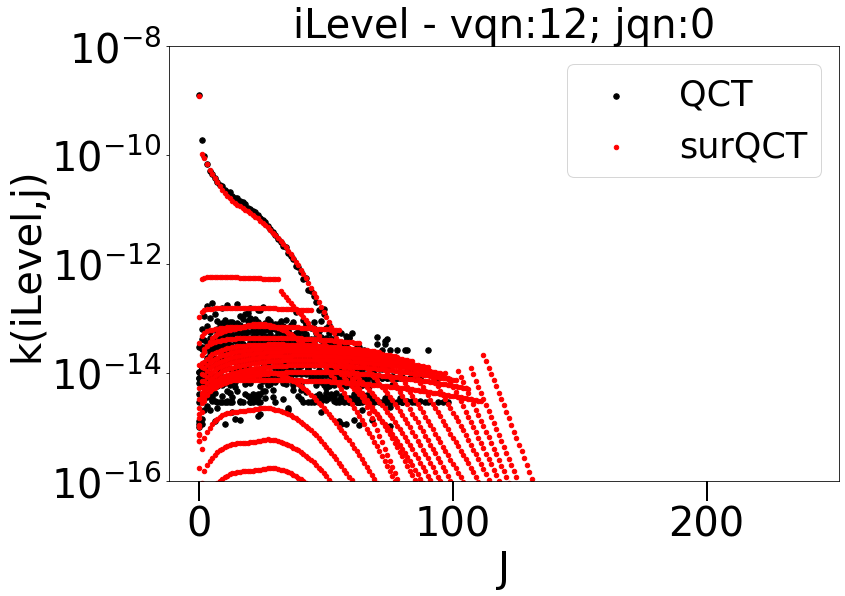

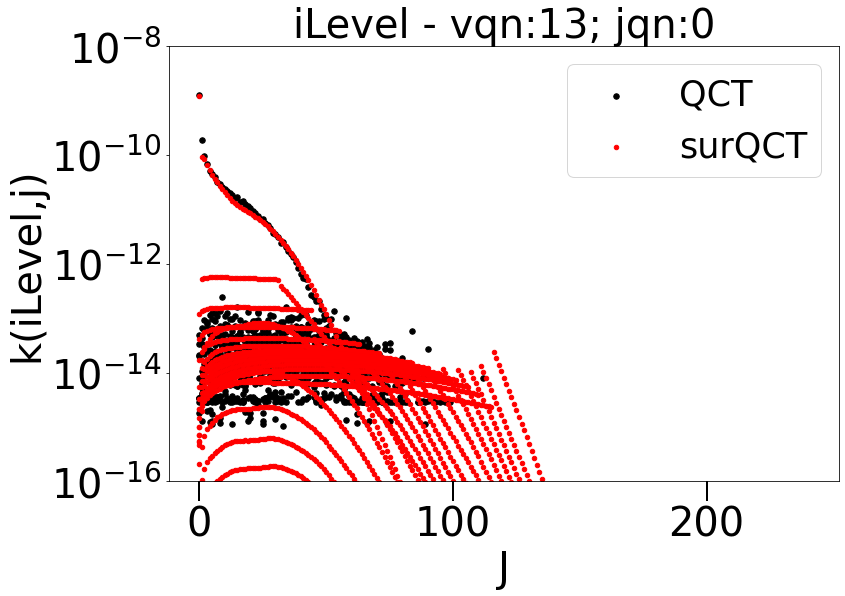

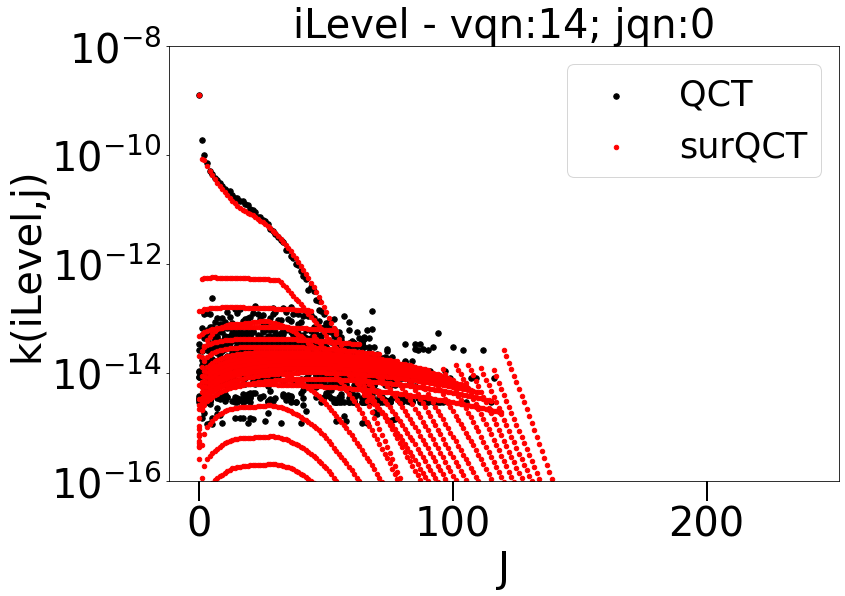

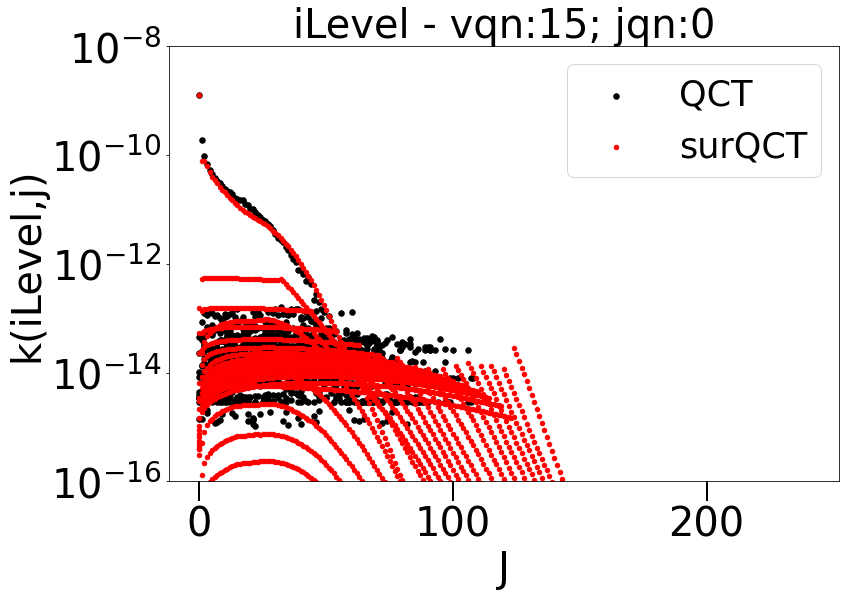

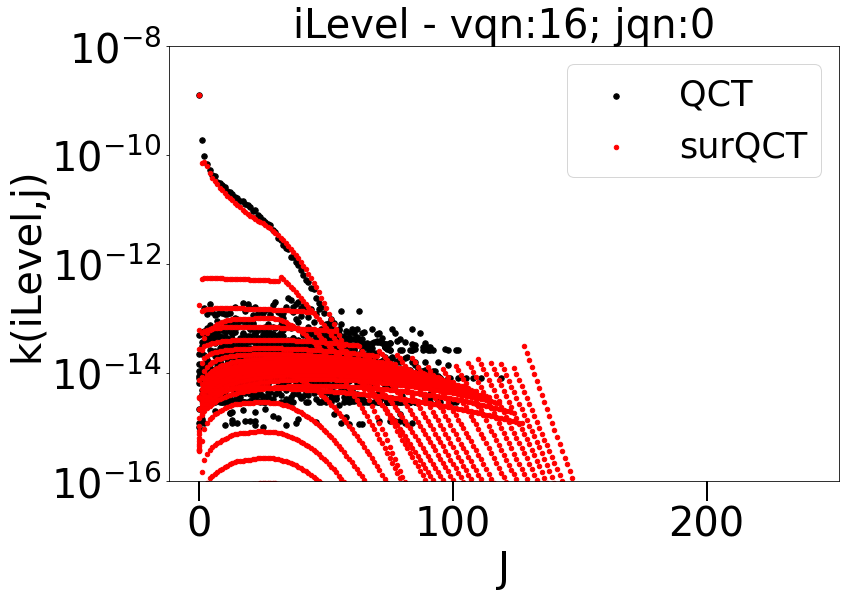

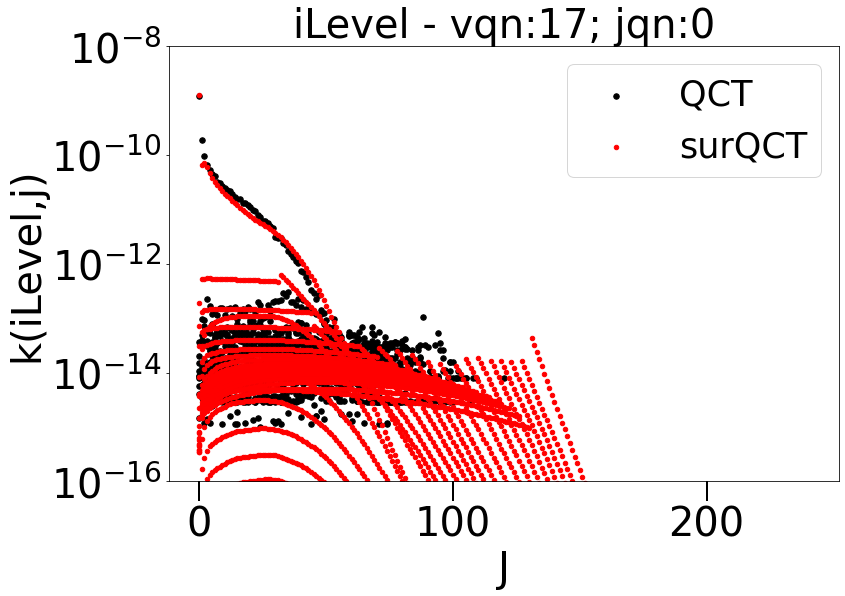

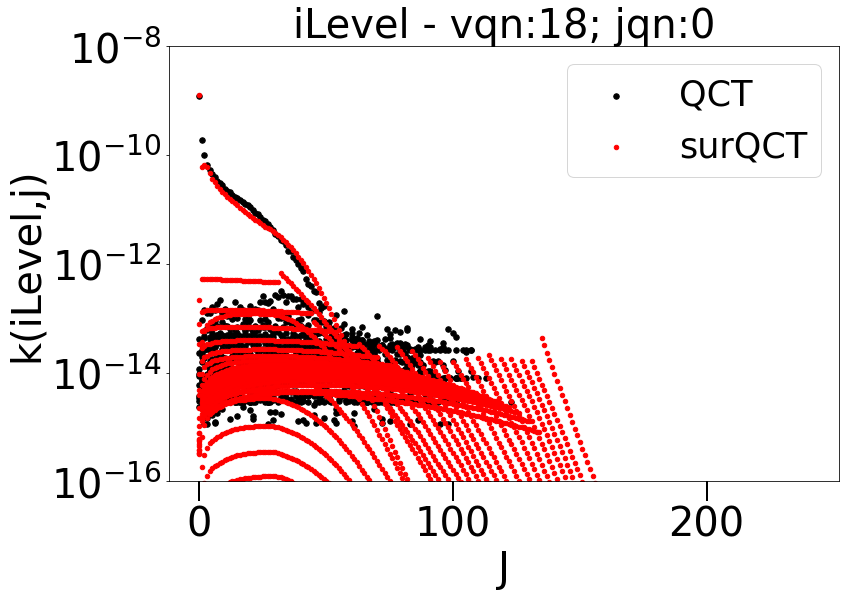

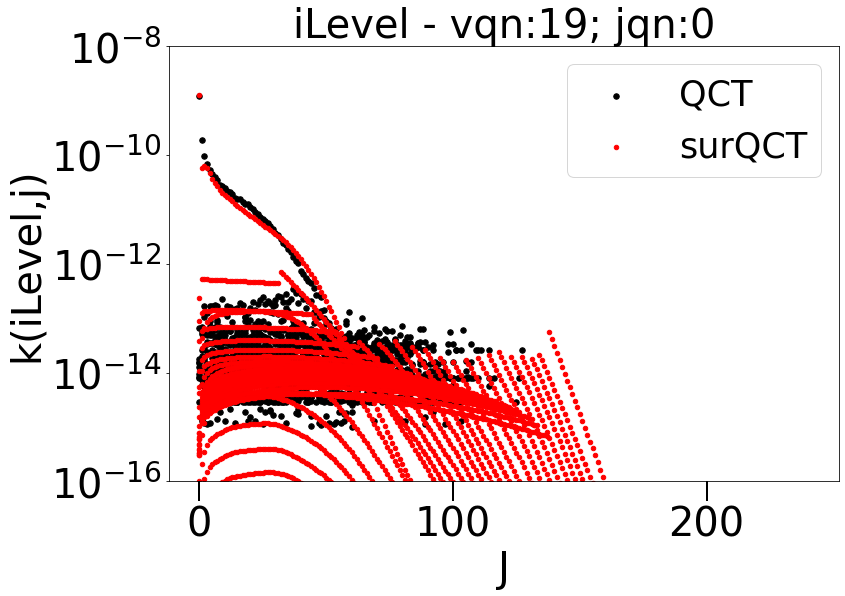

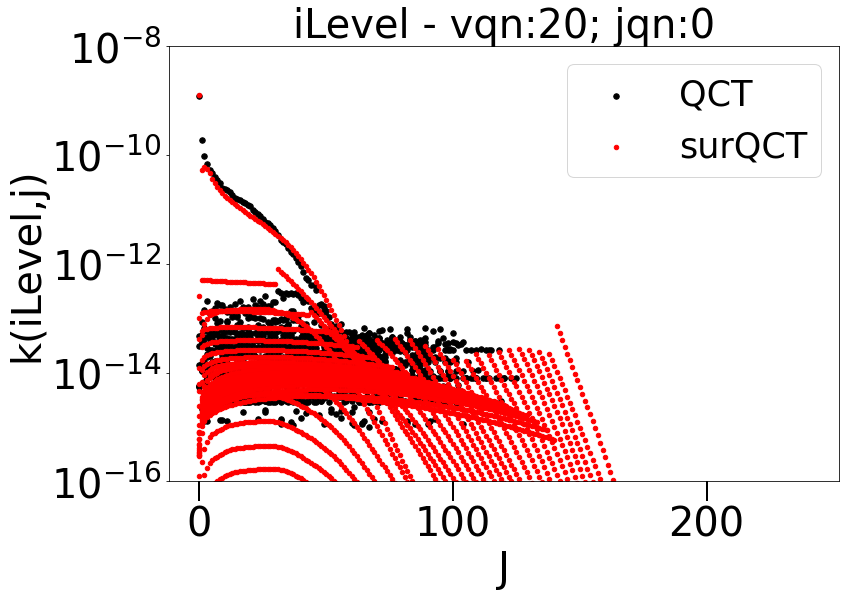

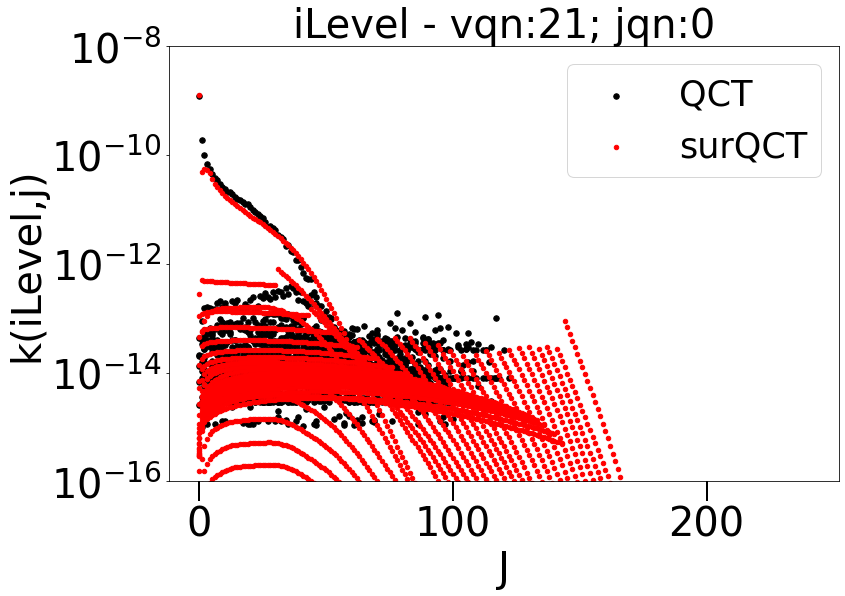

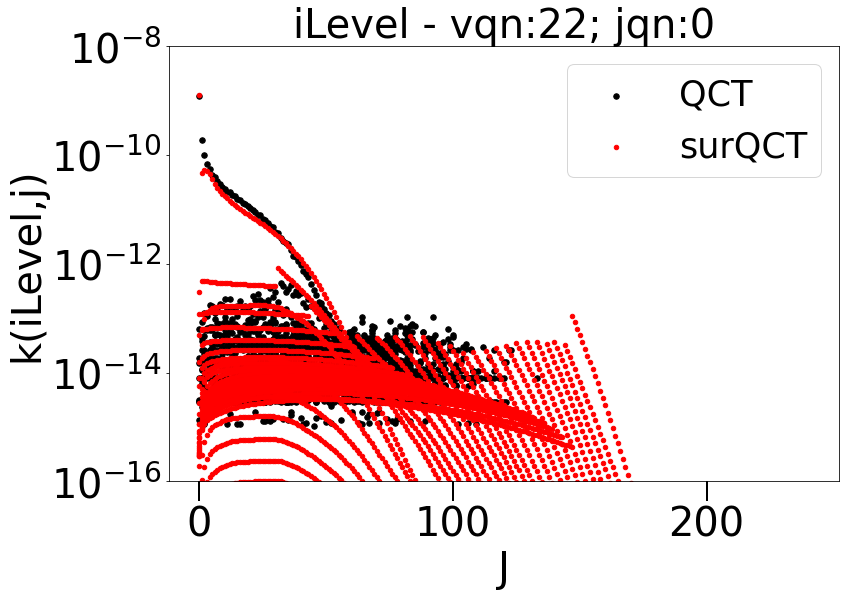

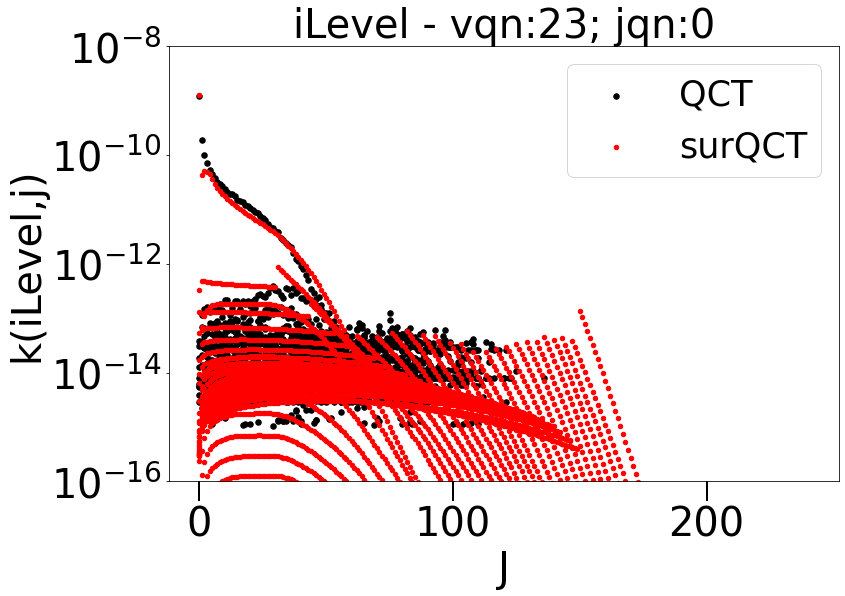

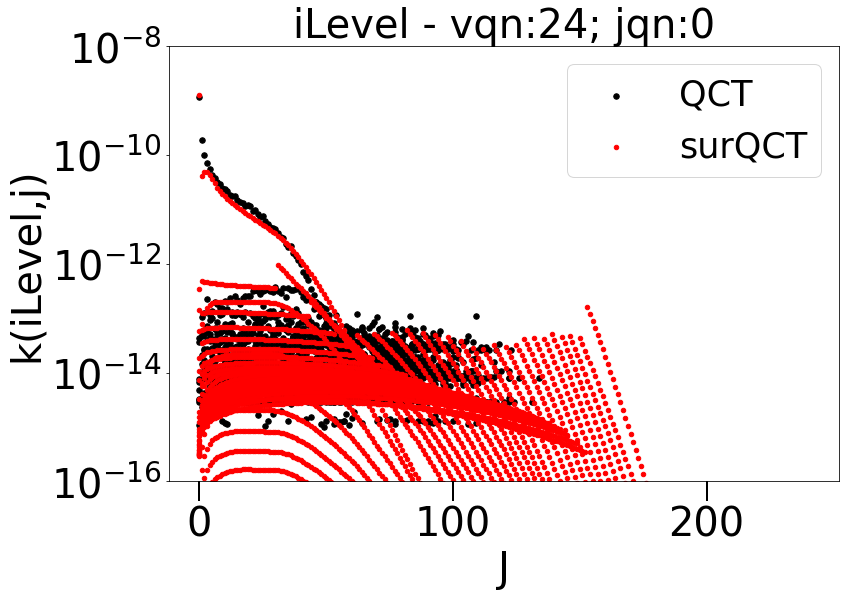

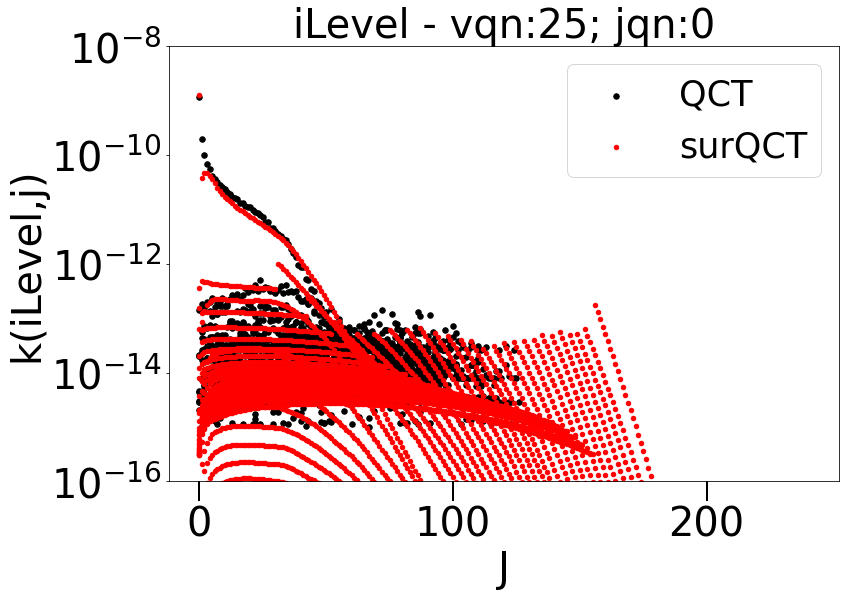

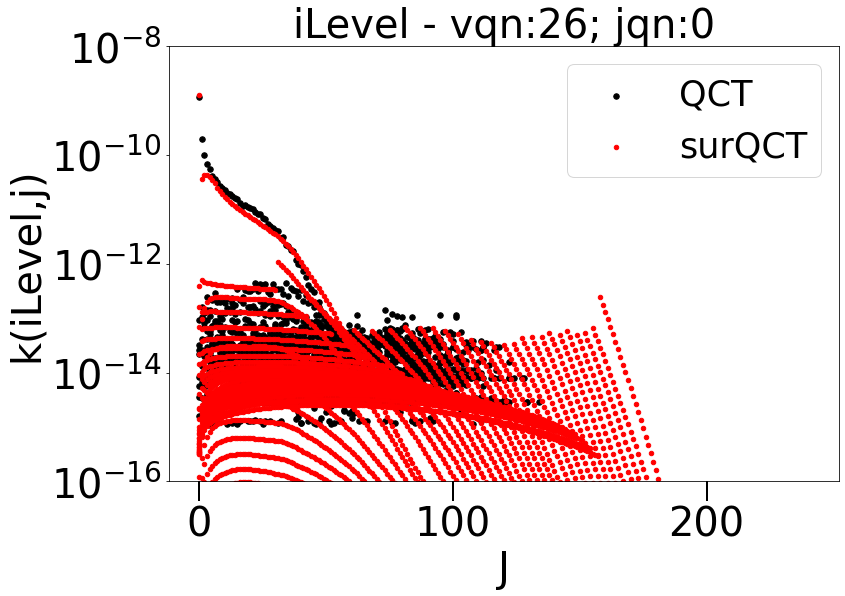

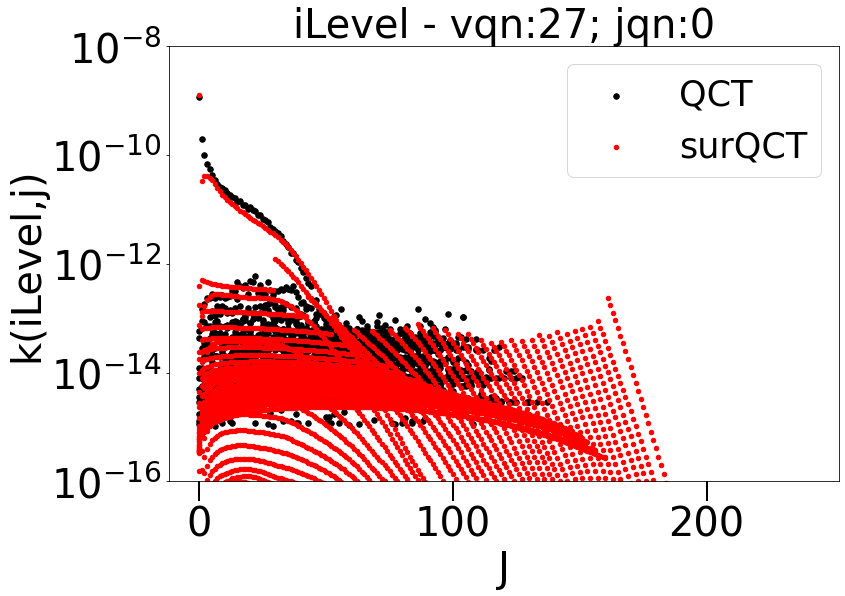

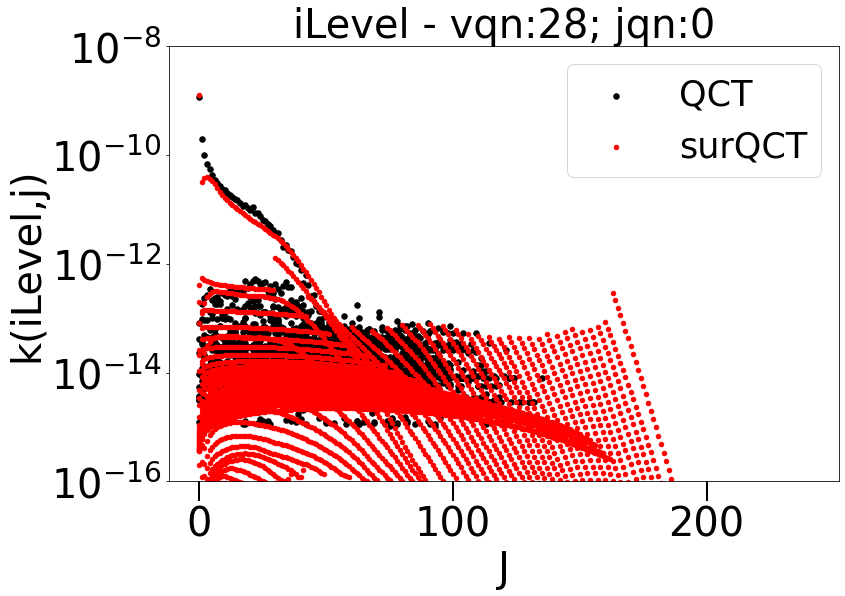

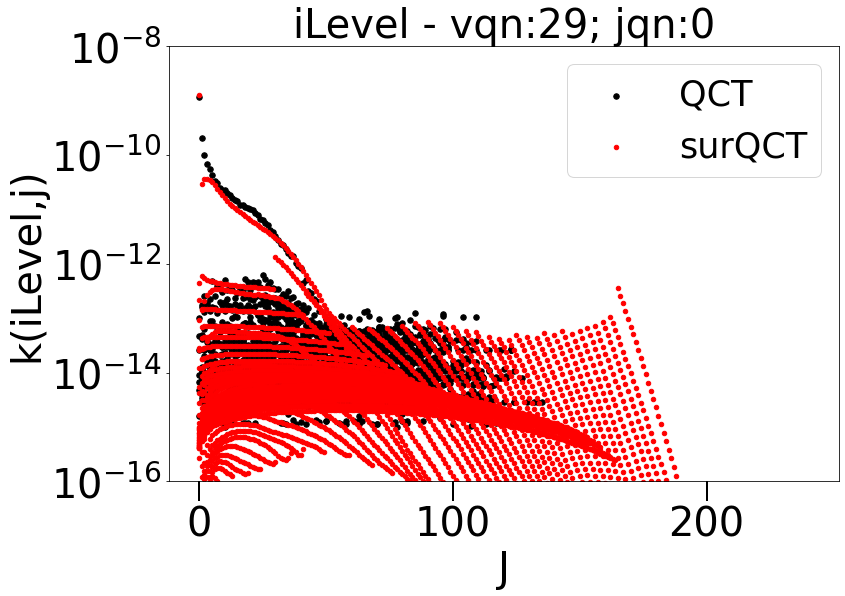

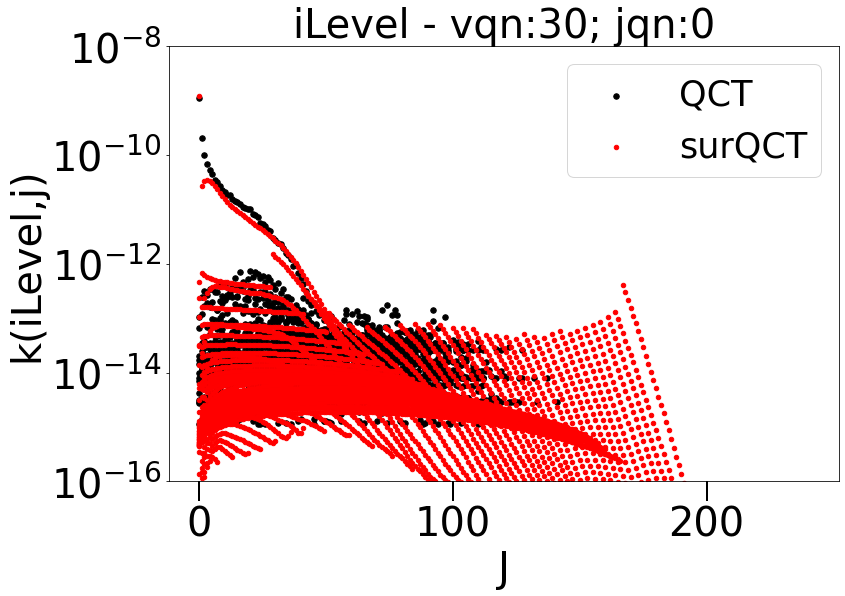

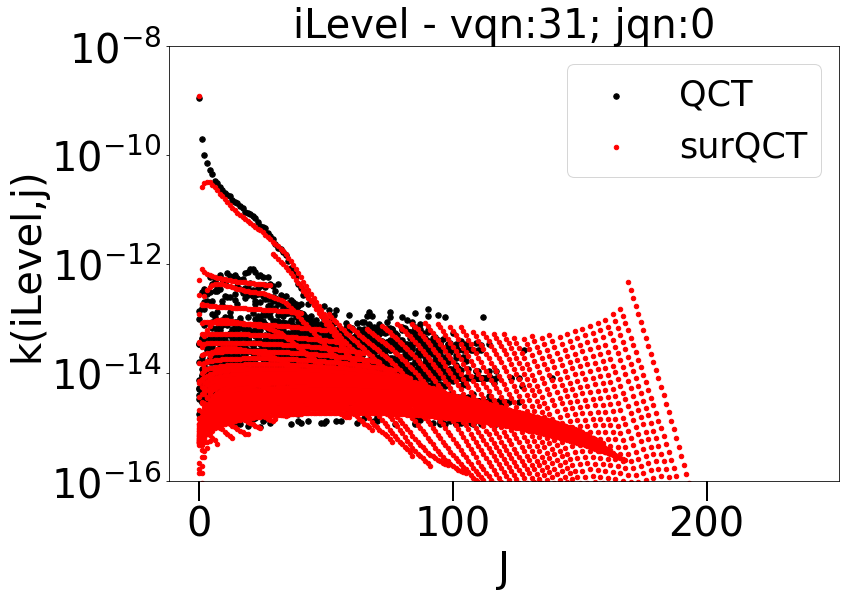

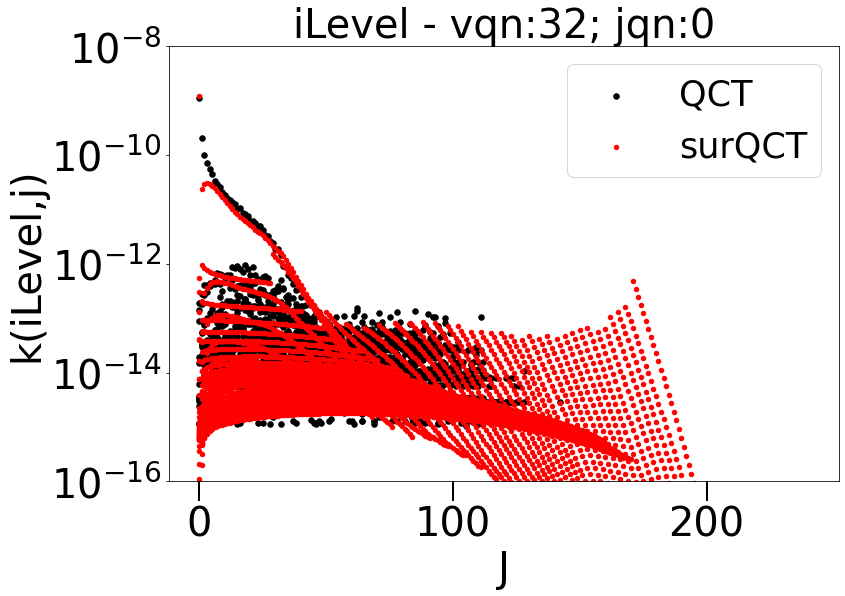

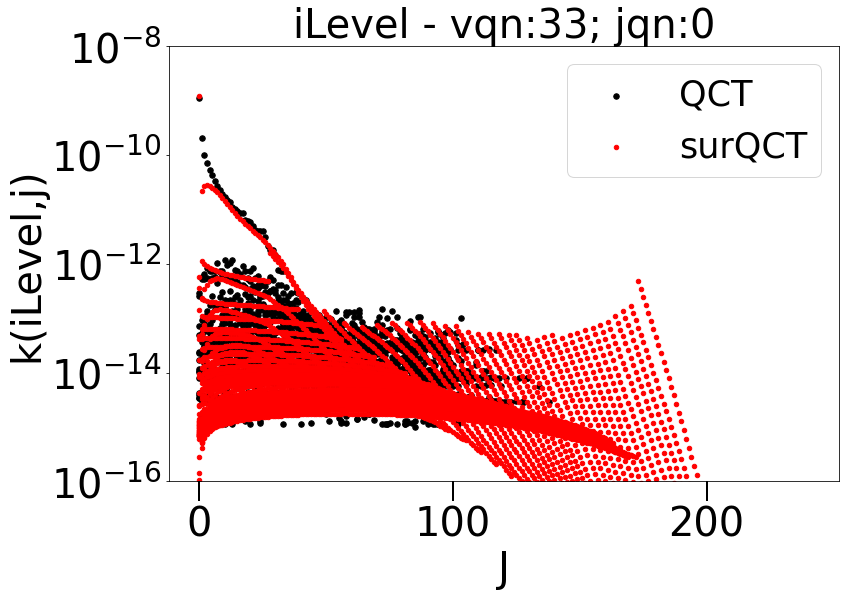

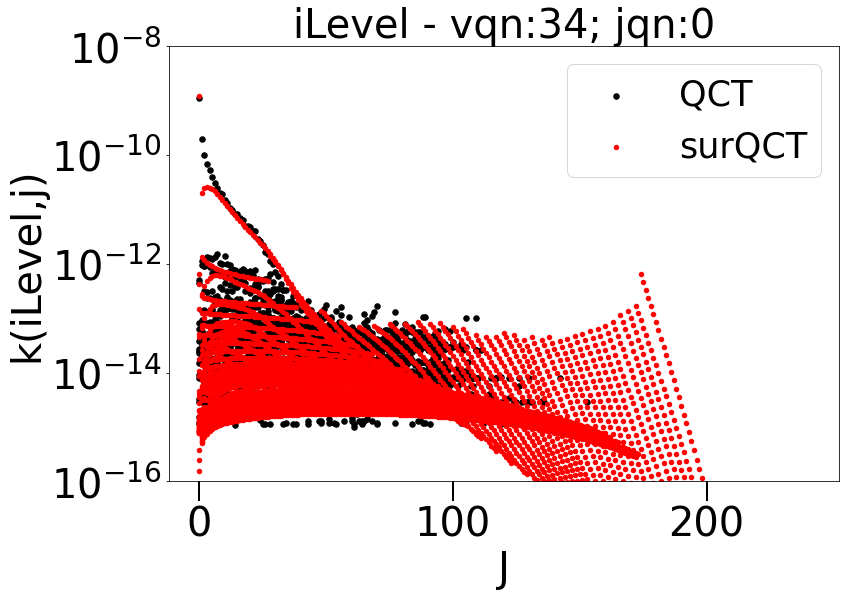

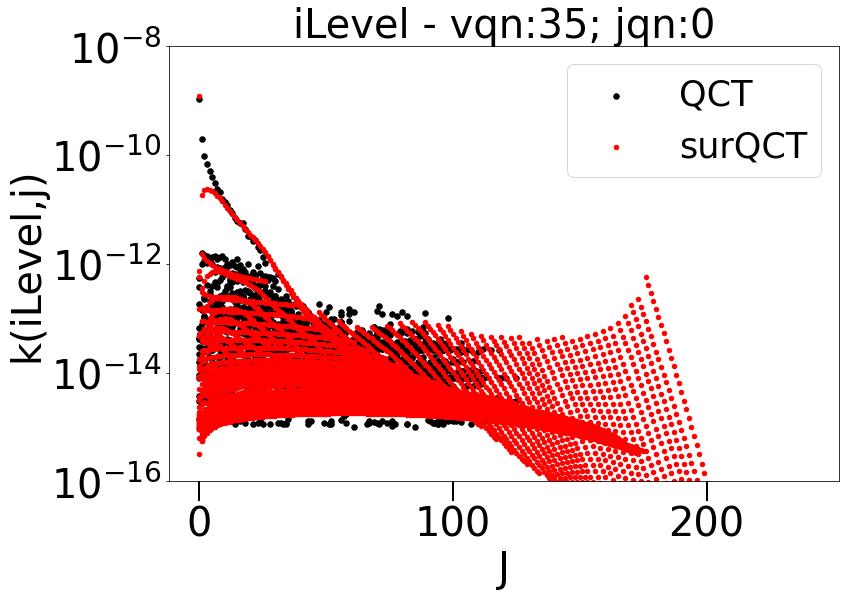

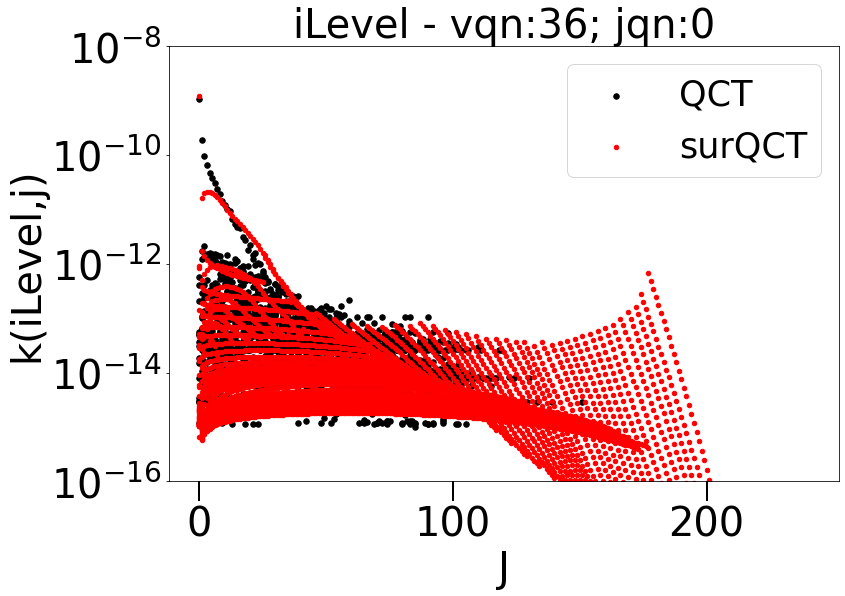

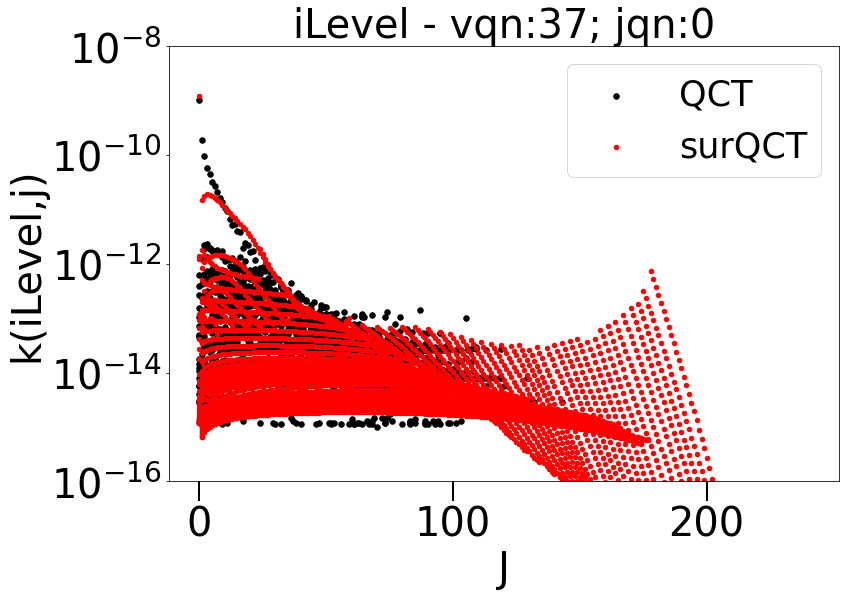

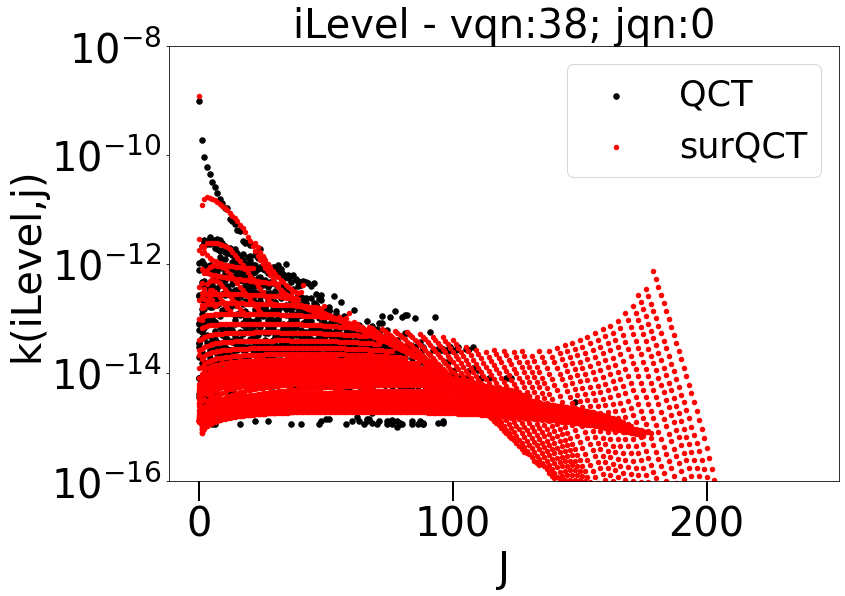

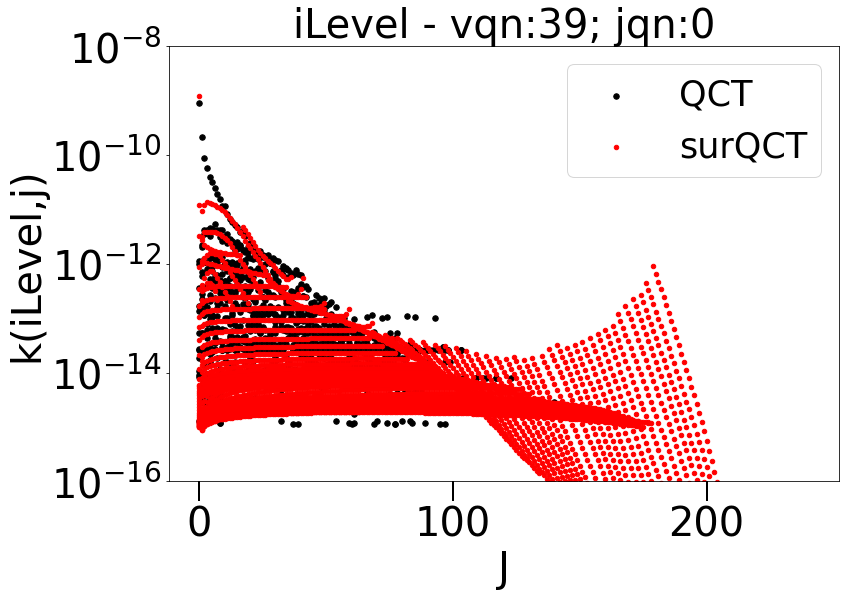

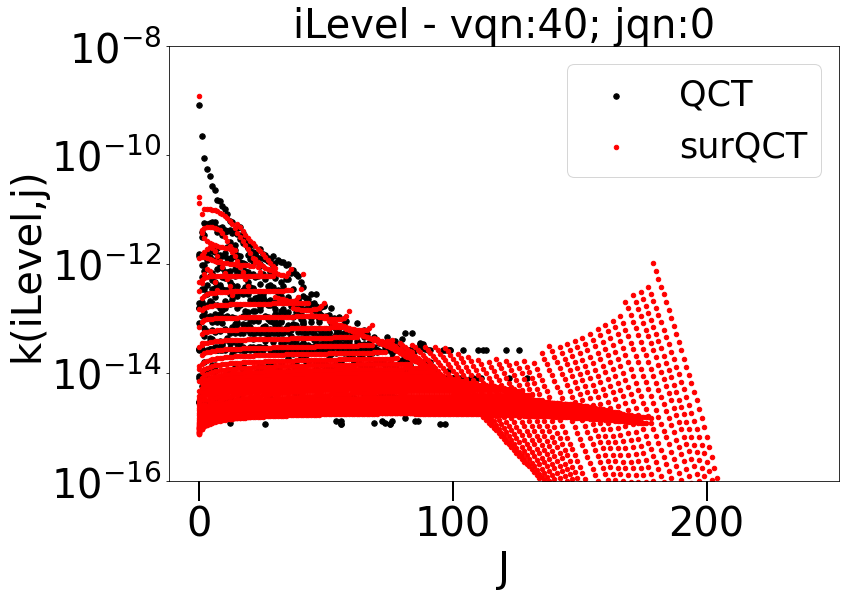

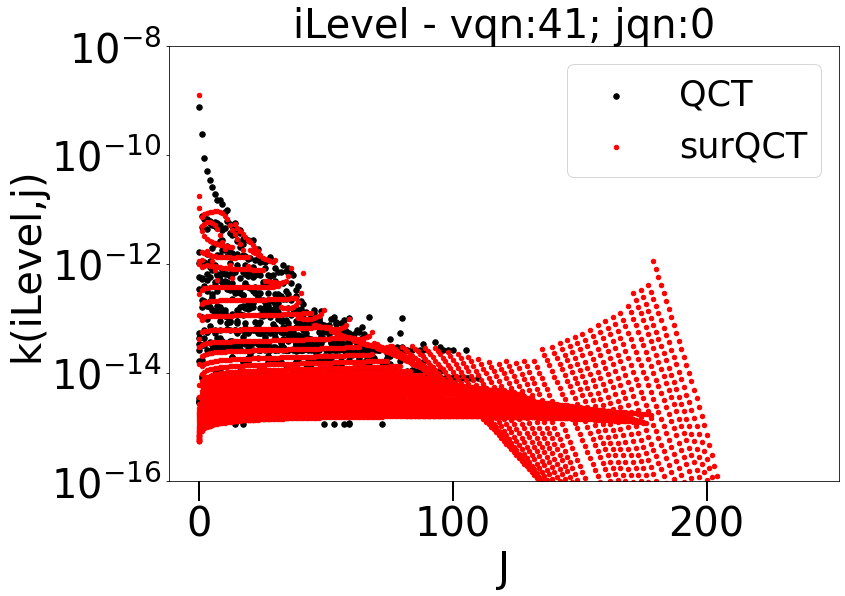

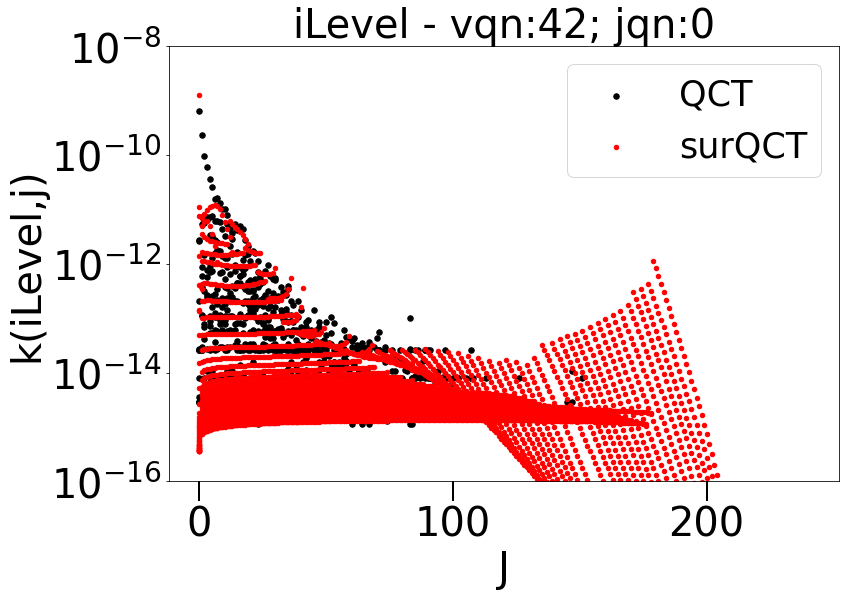

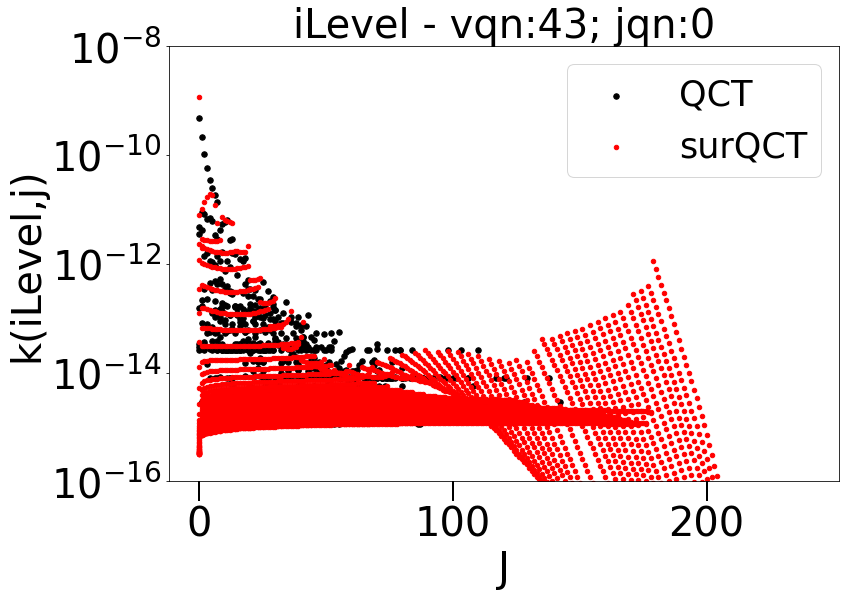

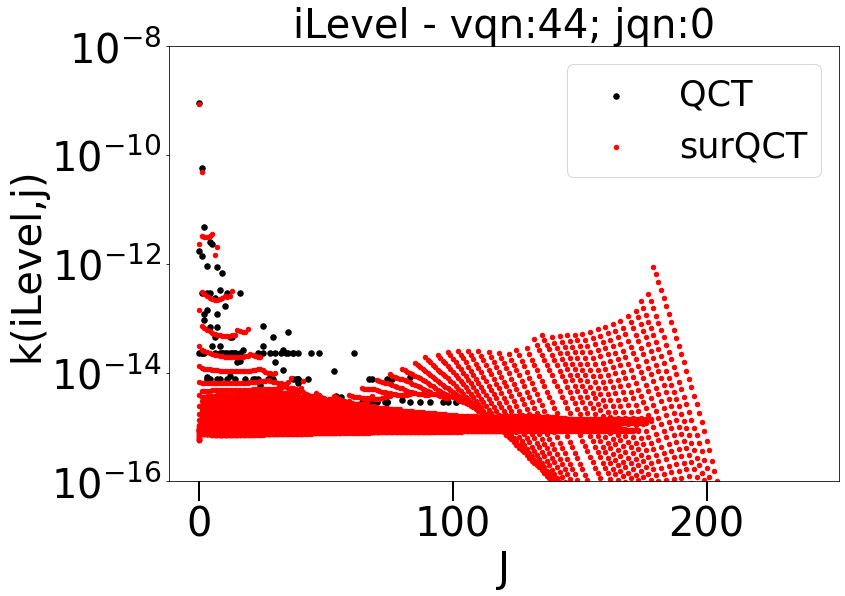

In [16]:
%matplotlib inline 
JqnVec_toWrite=np.linspace(0, 1, num=1, endpoint=False,dtype=int)
JqnVec = DiatData[0]['jqn'].to_numpy(int)

# iIdxVec             = np.array([4580, 4581], dtype=int)
# iIdxVec             = np.array([1,3], dtype=int)
iIdxVec=np.empty(0,dtype=int)

for i in range(np.size(JqnVec_toWrite)):    
    iDxVecTemp = [idx+1 for idx in np.arange(NLevels[0]) if (JqnVec[idx] == JqnVec_toWrite[i])]
    iIdxVec=np.append(iIdxVec,iDxVecTemp)

print(iIdxVec)


### Loop on Initial States
Str = 'q_'+str(int(TTran))
for iIdx in tqdm(iIdxVec, desc='[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes'):
    iIdx -= 1
    print('Level: '+str(iIdx)+'; vqn: '+str(DiatData[0]['vqn'].to_numpy()[iIdx])+'; jqn:'+str(DiatData[0]['jqn'].to_numpy()[iIdx]))
    time.sleep(0.02)
    
    if (InputData.ExoEndoFlg):
        jIdxVec           = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] <= DiatData[0]['EInt'].to_numpy()[iIdx])]
        jIdxVecNo         = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] > DiatData[0]['EInt'].to_numpy()[iIdx])]
        RatioNo           = [DiatData[0][Str].to_numpy()[iIdx]/DiatData[1][Str].to_numpy()[jIdx] for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] > DiatData[0]['EInt'].to_numpy()[iIdx])]
    else:
        jIdxVec           = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    >= DiatData[0][Str].to_numpy()[iIdx])]
        jIdxVecNo         = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    < DiatData[0][Str].to_numpy()[iIdx])]
        RatioNo           = [DiatData[0][Str].to_numpy()[iIdx]/DiatData[1][Str].to_numpy()[jIdx] for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    < DiatData[0][Str].to_numpy()[iIdx])]
    jNLevels              = len(jIdxVec)
    jNLevelsNo            = len(jIdxVecNo)  
    
    ### FWD Rates
    iiIdxVec              = [iIdx]*jNLevels
    
    TTranVec              = np.ones((jNLevels))*TTran
    TTranDataTemp         = pd.DataFrame({'TTran': TTranVec})
    TTranDataTemp.index   = jIdxVec

    
    iLevelsDataTemp       = LevelsData[0].iloc[iiIdxVec,:].copy()
    iLevelsDataTemp.index = jIdxVec

    jLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    if (OtherVar == '_Delta'):
        jLevelsDataTemp   = iLevelsDataTemp.subtract(jLevelsDataTemp) 
    else:
        jLevelsDataTemp   = jLevelsDataTemp
    jLevelsDataTemp.index = jIdxVec
    
    kLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    kLevelsDataTemp.index = jIdxVec

    
    iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    iLevelsData.columns   = [(VarName + '_i') for VarName in iLevelsData.columns]
    
    jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
    jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

    kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    kLevelsData.columns   = [(VarName + '_j') for VarName in kLevelsData.columns]
    
    xTemp_FWD             = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)

    
    x1 = iLevelsData[xTrainingVars[0:5]].to_numpy()
    x2 = jLevelsData[xTrainingVars[5:10]].to_numpy()    

    x = [x1,x2]
        
    if (len(xTemp_FWD[xTrainingVars]) > 0):
        KExcit_NN_FWD          = np.exp( model.net.predict(x) ) / InputData.MultFact  
    
    ## BWD Rates
    iiIdxVec              = jIdxVecNo
    jIdxVec               = [iIdx]*jNLevelsNo
    
    TTranVec              = np.ones((jNLevelsNo))*TTran
    TTranDataTemp         = pd.DataFrame({'TTran': TTranVec})
    TTranDataTemp.index   = iiIdxVec

    
    iLevelsDataTemp       = LevelsData[0].iloc[iiIdxVec,:].copy()
    iLevelsDataTemp.index = iiIdxVec

    jLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy() 
    jLevelsDataTemp.index = iiIdxVec
    if (OtherVar == '_Delta'):
        jLevelsDataTemp   = iLevelsDataTemp.subtract(jLevelsDataTemp) 
    else:
        jLevelsDataTemp   = jLevelsDataTemp
    
    kLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    kLevelsDataTemp.index = iiIdxVec

    
    iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    iLevelsData.columns   = [(VarName + '_i') for VarName in iLevelsData.columns]
    
    jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
    jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

    kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    kLevelsData.columns   = [(VarName + '_j') for VarName in kLevelsData.columns]
    
    xTempp_BWD            = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)
    
    x1 = iLevelsData[xTrainingVars[0:5]].to_numpy()
    x2 = jLevelsData[xTrainingVars[5:10]].to_numpy()    
    x = [x1,x2]
    
    if (len(xTempp_BWD[xTrainingVars]) > 0):
        KExcit_NN_BWD          = np.exp( model.net.predict(x) ) / InputData.MultFact 
        KExcit_NN_BWD[:,0]     = KExcit_NN_BWD[:,0] / RatioNo

        iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
        iLevelsData.columns   = [(VarName + '_j') for VarName in iLevelsData.columns]

        jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
        jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

        kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
        kLevelsData.columns   = [(VarName + '_i') for VarName in kLevelsData.columns]

        xTemp_BWD             = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)
        
    ### Concatenating
        if (len(xTemp_FWD[xTrainingVars]) > 0):
            xTemp     = pd.concat([xTemp_FWD, xTemp_BWD], axis=0)
            KExcit_NN = np.concatenate((KExcit_NN_FWD, KExcit_NN_BWD), axis=0)
        else:
            xTemp     = xTemp_BWD
            KExcit_NN = KExcit_NN_BWD
    else:
        if (len(xTemp_FWD[xTrainingVars]) > 0):
            xTemp     = xTemp_FWD
            KExcit_NN = KExcit_NN_FWD   
    
    ### Plotting
    Mask     = KExcit[iIdx,:] > 1e-15
    
    j_color = xTemp['jqn_j'] % 2
    v_color = DiatData[1]['vqn'][Mask] == 1
    cmap=mpl.colors.ListedColormap(["navy","crimson","limegreen","gold","k","r","b","y","c"])
    cmap1=mpl.colors.ListedColormap(["k","limegreen"])
    fig = plt.figure(figsize=(12,8))

    label_plot = "iLevel - vqn:" + str(DiatData[0]['vqn'].to_numpy()[iIdx])+"; jqn:"+str(DiatData[0]['jqn'].to_numpy()[iIdx])
    plt.scatter(DiatData[1]['jqn'][Mask], KExcit[iIdx,Mask], c='k', s=30,label='QCT')
    plt.scatter(xTemp['jqn_j'], KExcit_NN[:,0], s=20, c='r', label='surQCT')
    plt.yscale('log')
    plt.legend(['QCT','surQCT'])
    plt.ylim([1.e-16, 1.e-8])
    plt.xlabel('J')
    plt.ylabel('k(iLevel,j)')
    plt.title(label_plot)